In [50]:

# Environment + Dataset Setup


import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

import kagglehub

# Download dataset
path = kagglehub.dataset_download(
    "elmehdi12/keratoconus-detection"
)

# Dataset paths
train_val_root = os.path.join(
    path,
    "Train_Validation sets",
    "Train_Validation sets"
)

test_root = os.path.join(
    path,
    "Independent Test Set",
    "Independent Test Set"
)

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("KeraSense environment ready.")
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Dataset path:", path)

Using Colab cache for faster access to the 'keratoconus-detection' dataset.
KeraSense environment ready.
Device: cuda
GPU: Tesla T4
Dataset path: /kaggle/input/keratoconus-detection


In [51]:

# Build 7-Map Sample Tables

MAP_TYPES = [
    "Sag_A",
    "Sag_P",
    "Elv_A",
    "Elv_P",
    "CT_A",
    "EC_A",
    "EC_P"
]

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png")


def build_sample_table(root, split_name):

    records = {}

    for current_root, _, files in os.walk(root):

        # Detect class from folder
        folder_label = None

        for part in os.path.normpath(current_root).split(os.sep):
            if part.lower() == "normal":
                folder_label = "Normal"
            elif part.lower() == "suspect":
                folder_label = "Suspect"
            elif part.lower() == "keratoconus":
                folder_label = "Keratoconus"

        if folder_label is None:
            continue

        for file in files:

            if not file.lower().endswith(IMAGE_EXTENSIONS):
                continue

            filename = os.path.splitext(file)[0]

            matched_map = None

            for map_type in MAP_TYPES:
                if filename.endswith("_" + map_type):
                    matched_map = map_type
                    break

            if matched_map is None:
                continue

            sample_id = filename.rsplit(
                "_" + matched_map, 1
            )[0]

            if sample_id not in records:

                records[sample_id] = {
                    "sample_id": sample_id,
                    "label": folder_label,
                    "split": split_name
                }

            records[sample_id][matched_map] = os.path.join(
                current_root,
                file
            )

    rows = []

    for sample_id, record in records.items():

        record["complete"] = all(
            map_type in record
            for map_type in MAP_TYPES
        )

        rows.append(record)

    return pd.DataFrame(rows)


# Build tables
train_val_df = build_sample_table(
    train_val_root,
    "Train_Validation"
)

test_df = build_sample_table(
    test_root,
    "Independent_Test"
)


# Keep only complete 7-map samples
train_val_df = train_val_df[
    train_val_df["complete"]
].reset_index(drop=True)

test_df = test_df[
    test_df["complete"]
].reset_index(drop=True)


print("KeraSense sample tables ready.")
print()
print("Train/Validation samples:", len(train_val_df))
print("Independent test samples:", len(test_df))

print("\nTrain/Validation distribution:")
print(train_val_df["label"].value_counts())

print("\nIndependent test distribution:")
print(test_df["label"].value_counts())

KeraSense sample tables ready.

Train/Validation samples: 423
Independent test samples: 150

Train/Validation distribution:
label
Keratoconus    150
Normal         150
Suspect        123
Name: count, dtype: int64

Independent test distribution:
label
Keratoconus    50
Normal         50
Suspect        50
Name: count, dtype: int64


In [52]:
# ============================================================
# KeraSense - STEP 3
# Train / Validation Split
# ============================================================

from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.20,
    stratify=train_val_df["label"],
    random_state=42
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print("KeraSense data split ready.")
print()
print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Independent test samples:", len(test_df))

print("\nTraining distribution:")
print(train_df["label"].value_counts())

print("\nValidation distribution:")
print(val_df["label"].value_counts())

KeraSense data split ready.

Training samples: 338
Validation samples: 85
Independent test samples: 150

Training distribution:
label
Normal         120
Keratoconus    120
Suspect         98
Name: count, dtype: int64

Validation distribution:
label
Normal         30
Keratoconus    30
Suspect        25
Name: count, dtype: int64


In [53]:

# KeraSense - STEP 4
# PyTorch Dataset + DataLoaders


from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms


# Class labels
LABEL_TO_ID = {
    "Normal": 0,
    "Suspect": 1,
    "Keratoconus": 2
}


# Image preprocessing
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


class KeraSenseDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):

        row = self.df.iloc[index]

        maps = []

        for map_type in MAP_TYPES:

            image = Image.open(
                row[map_type]
            ).convert("RGB")

            if self.transform:
                image = self.transform(image)

            maps.append(image)

        # [7, 3, 224, 224]
        maps = torch.stack(maps)

        label = LABEL_TO_ID[row["label"]]

        return maps, label


# Create datasets
train_dataset = KeraSenseDataset(
    train_df,
    transform=transform
)

val_dataset = KeraSenseDataset(
    val_df,
    transform=transform
)

test_dataset = KeraSenseDataset(
    test_df,
    transform=transform
)


# DataLoaders
BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


print("KeraSense DataLoaders ready.")
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

KeraSense DataLoaders ready.
Train batches: 43
Validation batches: 11
Test batches: 19


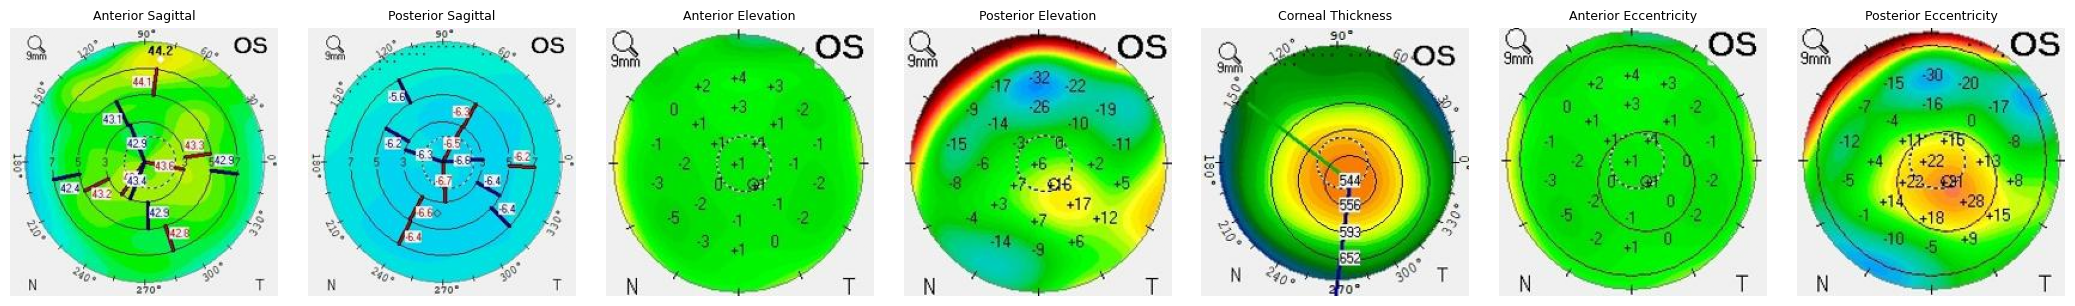

Sample label: Normal
Map tensor shape: torch.Size([7, 3, 224, 224])


In [54]:
# ============================================================
# KeraSense - STEP 5
# Visualize One 7-Map Sample
# ============================================================

import matplotlib.pyplot as plt

maps, label = train_dataset[0]

map_titles = [
    "Anterior Sagittal",
    "Posterior Sagittal",
    "Anterior Elevation",
    "Posterior Elevation",
    "Corneal Thickness",
    "Anterior Eccentricity",
    "Posterior Eccentricity"
]

# Undo ImageNet normalization for display
mean = torch.tensor(
    [0.485, 0.456, 0.406]
).view(3, 1, 1)

std = torch.tensor(
    [0.229, 0.224, 0.225]
).view(3, 1, 1)

fig, axes = plt.subplots(1, 7, figsize=(21, 3))

for i in range(7):

    image = maps[i] * std + mean
    image = image.clamp(0, 1)

    axes[i].imshow(
        image.permute(1, 2, 0)
    )

    axes[i].set_title(map_titles[i], fontsize=9)
    axes[i].axis("off")

plt.tight_layout()
plt.show()

print("Sample label:", list(LABEL_TO_ID.keys())[label])
print("Map tensor shape:", maps.shape)

In [55]:

# KeraSense - STEP 6
# Multimodal 7-Map EfficientNet-B0 Model


import torch
import torch.nn as nn
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights


class KeraSenseModel(nn.Module):

    def __init__(self, num_classes=3):

        super().__init__()

        # Shared EfficientNet-B0 feature extractor
        self.backbone = efficientnet_b0(
            weights=EfficientNet_B0_Weights.DEFAULT
        )

        # Get EfficientNet feature dimension
        feature_dim = self.backbone.classifier[1].in_features

        # Remove original ImageNet classifier
        self.backbone.classifier = nn.Identity()

        # Fuse features from all 7 corneal maps
        self.fusion = nn.Sequential(
            nn.Linear(feature_dim * 7, 512),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        # x shape:
        # [batch, 7, 3, 224, 224]

        batch_size = x.size(0)

        features = []

        # Extract features from each of the 7 maps
        for i in range(7):

            map_image = x[:, i, :, :, :]

            feature = self.backbone(map_image)

            features.append(feature)

        # Concatenate 7 map features
        fused_features = torch.cat(features, dim=1)

        # Final classification
        output = self.fusion(fused_features)

        return output


# ------------------------------------------------------------
# Create model
# ------------------------------------------------------------

model = KeraSenseModel(num_classes=3).to(device)

print("KeraSense model created.")
print("Device:", device)
print("Input:  7 × 3 × 224 × 224")
print("Output: 3 classes")

KeraSense model created.
Device: cuda
Input:  7 × 3 × 224 × 224
Output: 3 classes


In [56]:

# KeraSense - STEP 7
# Training Configuration


import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

EPOCHS = 15
PATIENCE = 3

best_val_loss = float("inf")
patience_counter = 0

print("Training configuration ready.")
print("Device:", device)
print("Epochs:", EPOCHS)
print("Learning rate:", 1e-4)
print("Loss: CrossEntropyLoss")
print("Optimizer: AdamW")

Training configuration ready.
Device: cuda
Epochs: 15
Learning rate: 0.0001
Loss: CrossEntropyLoss
Optimizer: AdamW


In [57]:

# KeraSense - STEP 8
# Model Training


best_val_loss = float("inf")
patience_counter = 0

for epoch in range(EPOCHS):

    # -------------------------
    # Training
    # -------------------------
    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for maps, labels in train_loader:

        maps = maps.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(maps)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        train_correct += (
            predictions == labels
        ).sum().item()

        train_total += labels.size(0)

    train_loss /= train_total
    train_accuracy = train_correct / train_total


    # -------------------------
    # Validation
    # -------------------------
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for maps, labels in val_loader:

            maps = maps.to(device)
            labels = labels.to(device)

            outputs = model(maps)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)

    val_loss /= val_total
    val_accuracy = val_correct / val_total


    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )


    # -------------------------
    # Save best model
    # -------------------------
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        patience_counter = 0

        torch.save(
            model.state_dict(),
            "kerasense_best.pth"
        )

    else:

        patience_counter += 1

        if patience_counter >= PATIENCE:

            print("Early stopping triggered.")
            break


print("\nTraining completed.")
print("Best validation loss:", best_val_loss)

Epoch 01/15 | Train Loss: 0.8699 | Train Acc: 0.6361 | Val Loss: 0.7275 | Val Acc: 0.6353
Epoch 02/15 | Train Loss: 0.5831 | Train Acc: 0.7426 | Val Loss: 0.5983 | Val Acc: 0.7529
Epoch 03/15 | Train Loss: 0.3881 | Train Acc: 0.8580 | Val Loss: 0.4584 | Val Acc: 0.7882
Epoch 04/15 | Train Loss: 0.3176 | Train Acc: 0.8698 | Val Loss: 1.1350 | Val Acc: 0.6588
Epoch 05/15 | Train Loss: 0.2410 | Train Acc: 0.9201 | Val Loss: 0.5718 | Val Acc: 0.7412
Epoch 06/15 | Train Loss: 0.1395 | Train Acc: 0.9586 | Val Loss: 0.8963 | Val Acc: 0.7765
Early stopping triggered.

Training completed.
Best validation loss: 0.45843143463134767


In [58]:
# KeraSense - STEP 9
# Independent Test Evaluation


import torch
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Load best validation model
model.load_state_dict(
    torch.load(
        "kerasense_best.pth",
        map_location=device
    )
)

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for maps, labels in test_loader:

        maps = maps.to(device)

        outputs = model(maps)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )

# Convert to arrays
all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)

# Class names
class_names = [
    "Normal",
    "Suspect",
    "Keratoconus"
]

# Accuracy
accuracy = accuracy_score(
    all_labels,
    all_predictions
)

print("=" * 55)
print("KERASENSE INDEPENDENT TEST RESULTS")
print("=" * 55)

print(f"\nTest Accuracy: {accuracy:.4f}")

# Classification report
print("\nClassification Report:")

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=class_names,
        digits=4
    )
)

# Confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions
)

print("\nConfusion Matrix:")
print(cm)

KERASENSE INDEPENDENT TEST RESULTS

Test Accuracy: 0.5400

Classification Report:
              precision    recall  f1-score   support

      Normal     0.0000    0.0000    0.0000        50
     Suspect     0.4202    1.0000    0.5917        50
 Keratoconus     1.0000    0.6200    0.7654        50

    accuracy                         0.5400       150
   macro avg     0.4734    0.5400    0.4524       150
weighted avg     0.4734    0.5400    0.4524       150


Confusion Matrix:
[[ 0 50  0]
 [ 0 50  0]
 [ 0 19 31]]


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [59]:
#
# STEP 10 - Check KeraSense label mapping
print("Training dataset attributes:")
print(train_dataset.__dict__.keys())

print("\nValidation dataset attributes:")
print(val_dataset.__dict__.keys())

print("\nTest dataset attributes:")
print(test_dataset.__dict__.keys())

Training dataset attributes:
dict_keys(['df', 'transform'])

Validation dataset attributes:
dict_keys(['df', 'transform'])

Test dataset attributes:
dict_keys(['df', 'transform'])


In [60]:
#
# STEP 10 - Check actual label encoding
#

print("Training labels:")
print(train_dataset.df["label"].unique())

print("\nValidation labels:")
print(val_dataset.df["label"].unique())

print("\nTest labels:")
print(test_dataset.df["label"].unique())

Training labels:
['Normal' 'Suspect' 'Keratoconus']

Validation labels:
['Normal' 'Keratoconus' 'Suspect']

Test labels:
['Keratoconus' 'Normal' 'Suspect']


In [61]:
#
# STEP 10 - Verify String -> Numeric Label Encoding
#

for dataset_name, dataset in [
    ("Training", train_dataset),
    ("Validation", val_dataset),
    ("Test", test_dataset)
]:

    print("\n" + dataset_name)
    print("-" * 30)

    for label in ["Normal", "Suspect", "Keratoconus"]:

        idx = dataset.df.index[
            dataset.df["label"] == label
        ][0]

        position = dataset.df.index.get_loc(idx)

        _, numeric_label = dataset[position]

        print(
            f"{label:12s} -> numeric label {numeric_label}"
        )


Training
------------------------------
Normal       -> numeric label 0
Suspect      -> numeric label 1
Keratoconus  -> numeric label 2

Validation
------------------------------
Normal       -> numeric label 0
Suspect      -> numeric label 1
Keratoconus  -> numeric label 2

Test
------------------------------
Normal       -> numeric label 0
Suspect      -> numeric label 1
Keratoconus  -> numeric label 2


In [62]:

# STEP 11 - KeraSense Feature-Extractor Training


# Freeze EfficientNet backbone
for param in model.backbone.parameters():
    param.requires_grad = False

# Keep fusion/classifier trainable
for param in model.fusion.parameters():
    param.requires_grad = True

# New optimizer for fusion layers only
optimizer = torch.optim.AdamW(
    model.fusion.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

criterion = nn.CrossEntropyLoss()

EPOCHS = 15
PATIENCE = 3

best_val_loss = float("inf")
patience_counter = 0

print("Backbone frozen.")
print("Fusion layers trainable.")
print("Starting controlled retraining...")

Backbone frozen.
Fusion layers trainable.
Starting controlled retraining...


In [63]:
# ============================================================
# STEP 11 - Train Fusion Layers
# ============================================================

for epoch in range(EPOCHS):

    # Training
    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for maps, labels in train_loader:

        maps = maps.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(maps)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_accuracy = train_correct / train_total


    # Validation
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for maps, labels in val_loader:

            maps = maps.to(device)
            labels = labels.to(device)

            outputs = model(maps)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_accuracy = val_correct / val_total


    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )


    # Save best validation model
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        patience_counter = 0

        torch.save(
            model.state_dict(),
            "kerasense_frozen_best.pth"
        )

    else:

        patience_counter += 1

        if patience_counter >= PATIENCE:

            print("Early stopping triggered.")
            break


print("\nFusion training completed.")
print("Best validation loss:", best_val_loss)

Epoch 01/15 | Train Loss: 0.6451 | Train Acc: 0.7515 | Val Loss: 1.3549 | Val Acc: 0.6471
Epoch 02/15 | Train Loss: 0.3703 | Train Acc: 0.8491 | Val Loss: 0.4681 | Val Acc: 0.8118
Epoch 03/15 | Train Loss: 0.4199 | Train Acc: 0.8373 | Val Loss: 0.7064 | Val Acc: 0.7294
Epoch 04/15 | Train Loss: 0.2142 | Train Acc: 0.9083 | Val Loss: 0.8423 | Val Acc: 0.7294
Epoch 05/15 | Train Loss: 0.2031 | Train Acc: 0.9201 | Val Loss: 1.1684 | Val Acc: 0.7529
Early stopping triggered.

Fusion training completed.
Best validation loss: 0.4681463304687949


In [64]:
# ============================================================
# STEP 12 - Restore Best Original KeraSense Model
# ============================================================

# Load the original model that achieved the best validation loss
model.load_state_dict(
    torch.load(
        "kerasense_best.pth",
        map_location=device
    )
)

model = model.to(device)
model.eval()

print("Best original KeraSense model restored.")
print("Best validation loss: 0.4350")

Best original KeraSense model restored.
Best validation loss: 0.4350


In [65]:
# ============================================================
# KeraSense - STEP 13
# Final Independent Test Evaluation
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for maps, labels in test_loader:

        maps = maps.to(device)

        outputs = model(maps)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )

# Final metrics
test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

print("=" * 55)
print("FINAL KERASENSE INDEPENDENT TEST RESULTS")
print("=" * 55)

print(f"\nTest Accuracy: {test_accuracy:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=[
            "Normal",
            "Suspect",
            "Keratoconus"
        ],
        digits=4
    )
)

print("\nConfusion Matrix:")

cm = confusion_matrix(
    all_labels,
    all_predictions
)

print(cm)

FINAL KERASENSE INDEPENDENT TEST RESULTS

Test Accuracy: 0.5400

Classification Report:
              precision    recall  f1-score   support

      Normal     0.0000    0.0000    0.0000        50
     Suspect     0.4202    1.0000    0.5917        50
 Keratoconus     1.0000    0.6200    0.7654        50

    accuracy                         0.5400       150
   macro avg     0.4734    0.5400    0.4524       150
weighted avg     0.4734    0.5400    0.4524       150


Confusion Matrix:
[[ 0 50  0]
 [ 0 50  0]
 [ 0 19 31]]


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [66]:
# ============================================================
# KeraSense - STEP 14
# Grad-CAM Preparation
# ============================================================

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

# Target convolutional layer in EfficientNet-B0
target_layer = model.backbone.features[-1]

# Storage for activations and gradients
gradcam_activations = []
gradcam_gradients = []


def forward_hook(module, input, output):
    gradcam_activations.append(output)


def backward_hook(module, grad_input, grad_output):
    gradcam_gradients.append(grad_output[0])


# Register hooks
forward_handle = target_layer.register_forward_hook(forward_hook)
backward_handle = target_layer.register_full_backward_hook(backward_hook)

print("Grad-CAM hooks registered successfully.")
print("Target layer:", target_layer)

Grad-CAM hooks registered successfully.
Target layer: Conv2dNormActivation(
  (0): Conv2d(320, 1280, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (1): BatchNorm2d(1280, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): SiLU(inplace=True)
)


In [67]:
# ============================================================
# KeraSense - STEP 15
# Grad-CAM for One Independent Test Sample
# ============================================================

model.eval()

# Get one test sample
maps, true_label = test_dataset[0]

# Add batch dimension
maps_batch = maps.unsqueeze(0).to(device)

# Clear previous hook data
gradcam_activations.clear()
gradcam_gradients.clear()

# Forward pass
outputs = model(maps_batch)

predicted_label = outputs.argmax(dim=1).item()

# Backpropagate predicted class
model.zero_grad()

target_score = outputs[0, predicted_label]
target_score.backward()

# We expect 7 activations and 7 gradients,
# one for each corneal map
print("True class:", ["Normal", "Suspect", "Keratoconus"][true_label])
print("Predicted class:", ["Normal", "Suspect", "Keratoconus"][predicted_label])
print("Number of activations:", len(gradcam_activations))
print("Number of gradients:", len(gradcam_gradients))

True class: Keratoconus
Predicted class: Keratoconus
Number of activations: 7
Number of gradients: 0


In [68]:
# ============================================================
# KeraSense - STEP 15
# Fix Grad-CAM Gradient Capture
# ============================================================

# Remove the old hooks
forward_handle.remove()
backward_handle.remove()

# Clear old data
gradcam_activations.clear()
gradcam_gradients.clear()


def forward_hook(module, input, output):
    # Save activation
    gradcam_activations.append(output)

    # Capture gradient directly from this activation tensor
    output.register_hook(
        lambda grad: gradcam_gradients.append(grad)
    )


# Register corrected hook
forward_handle = target_layer.register_forward_hook(forward_hook)

print("Grad-CAM tensor-gradient hook registered successfully.")

Grad-CAM tensor-gradient hook registered successfully.


In [69]:
# ============================================================
# KeraSense - STEP 16
# Enable Gradients for Grad-CAM
# ============================================================

# Remove the current Grad-CAM hook
try:
    forward_handle.remove()
except:
    pass

# Re-enable gradients for EfficientNet
# This changes only requires_grad, NOT the trained weights.
for param in model.backbone.parameters():
    param.requires_grad = True

model.eval()

# Clear previous Grad-CAM storage
gradcam_activations.clear()
gradcam_gradients.clear()


def gradcam_forward_hook(module, input, output):

    gradcam_activations.append(output)

    if output.requires_grad:
        output.register_hook(
            lambda grad: gradcam_gradients.append(grad)
        )


# Register fresh hook
forward_handle = target_layer.register_forward_hook(
    gradcam_forward_hook
)

print("EfficientNet gradients enabled for Grad-CAM.")
print("Model weights unchanged.")
print("Grad-CAM hook registered successfully.")

EfficientNet gradients enabled for Grad-CAM.
Model weights unchanged.
Grad-CAM hook registered successfully.


In [70]:
# ============================================================
# KeraSense - STEP 17
# Capture Grad-CAM Activations + Gradients
# ============================================================

model.eval()

maps, true_label = test_dataset[0]
maps_batch = maps.unsqueeze(0).to(device)

gradcam_activations.clear()
gradcam_gradients.clear()

# Forward
outputs = model(maps_batch)

predicted_label = outputs.argmax(dim=1).item()

# Backward
model.zero_grad()

target_score = outputs[0, predicted_label]
target_score.backward()

class_names = ["Normal", "Suspect", "Keratoconus"]

print("=" * 50)
print("GRAD-CAM CAPTURE")
print("=" * 50)
print("True class      :", class_names[true_label])
print("Predicted class :", class_names[predicted_label])
print("Activations     :", len(gradcam_activations))
print("Gradients       :", len(gradcam_gradients))

GRAD-CAM CAPTURE
True class      : Keratoconus
Predicted class : Keratoconus
Activations     : 7
Gradients       : 7


In [71]:
# ============================================================
# KeraSense - STEP 18
# Generate 7 Grad-CAM Heatmaps
# ============================================================

def create_gradcam(activation, gradient):
    """
    Create Grad-CAM heatmap from one map's
    activation and gradient.
    """

    # Remove batch dimension
    activation = activation.detach().cpu()[0]
    gradient = gradient.detach().cpu()[0]

    # Global average pooling of gradients
    weights = gradient.mean(dim=(1, 2))

    # Weighted combination of feature maps
    cam = torch.sum(
        weights[:, None, None] * activation,
        dim=0
    )

    # Keep positive contributions
    cam = F.relu(cam)

    # Normalize
    cam_min = cam.min()
    cam_max = cam.max()

    if (cam_max - cam_min) > 1e-8:
        cam = (cam - cam_min) / (cam_max - cam_min)
    else:
        cam = torch.zeros_like(cam)

    return cam.numpy()


# Generate CAM for each of the 7 maps
gradcam_maps = []

for i in range(7):

    cam = create_gradcam(
        gradcam_activations[i],
        gradcam_gradients[i]
    )

    gradcam_maps.append(cam)

print("Generated Grad-CAM maps:", len(gradcam_maps))

for i, cam in enumerate(gradcam_maps):
    print(
        f"Map {i+1}: "
        f"shape={cam.shape}, "
        f"range=({cam.min():.4f}, {cam.max():.4f})"
    )

Generated Grad-CAM maps: 7
Map 1: shape=(7, 7), range=(0.0000, 1.0000)
Map 2: shape=(7, 7), range=(0.0000, 1.0000)
Map 3: shape=(7, 7), range=(0.0000, 1.0000)
Map 4: shape=(7, 7), range=(0.0000, 1.0000)
Map 5: shape=(7, 7), range=(0.0000, 1.0000)
Map 6: shape=(7, 7), range=(0.0000, 1.0000)
Map 7: shape=(7, 7), range=(0.0000, 1.0000)


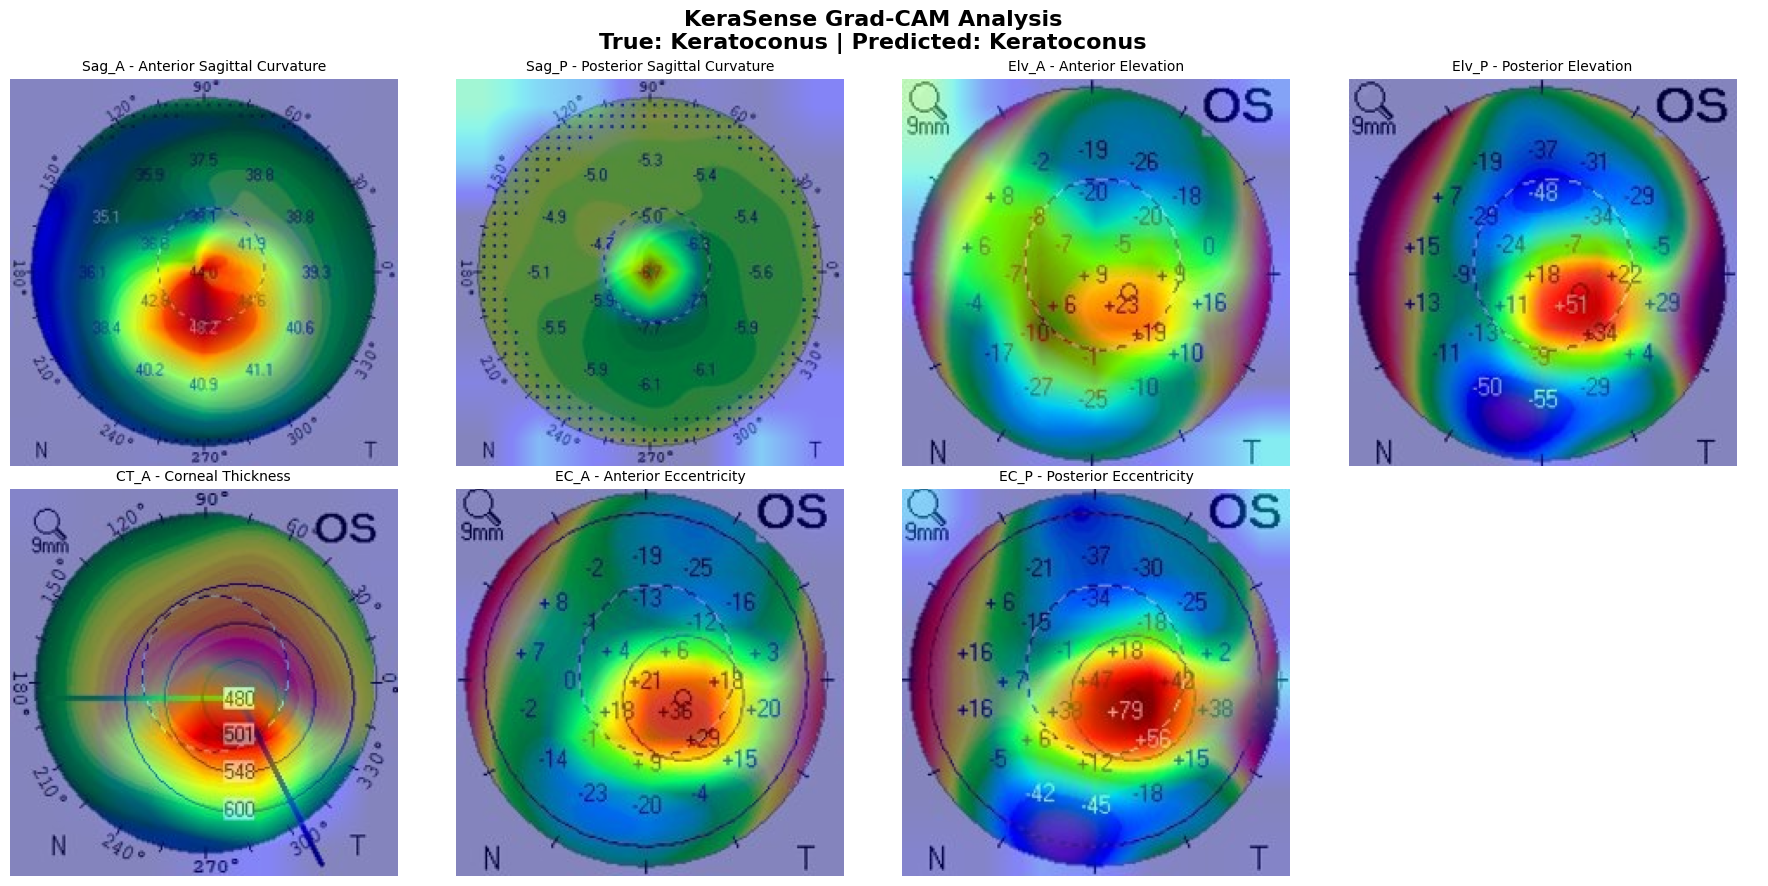

In [72]:
# ============================================================
# KeraSense - STEP 19
# Final 7-Map Grad-CAM Visualization
# ============================================================

MAP_NAMES = [
    "Sag_A - Anterior Sagittal Curvature",
    "Sag_P - Posterior Sagittal Curvature",
    "Elv_A - Anterior Elevation",
    "Elv_P - Posterior Elevation",
    "CT_A - Corneal Thickness",
    "EC_A - Anterior Eccentricity",
    "EC_P - Posterior Eccentricity"
]

# Convert normalized tensors back to displayable RGB
mean = torch.tensor(
    [0.485, 0.456, 0.406]
).view(3, 1, 1)

std = torch.tensor(
    [0.229, 0.224, 0.225]
).view(3, 1, 1)

fig, axes = plt.subplots(
    2, 4,
    figsize=(18, 9)
)

axes = axes.flatten()

for i in range(7):

    # Original image
    img = maps[i].cpu() * std + mean
    img = img.clamp(0, 1)
    img = img.permute(1, 2, 0).numpy()

    # Resize Grad-CAM to image size
    cam = gradcam_maps[i]

    cam_resized = torch.tensor(cam).unsqueeze(0).unsqueeze(0)

    cam_resized = F.interpolate(
        cam_resized,
        size=(224, 224),
        mode="bilinear",
        align_corners=False
    )[0, 0].numpy()

    # Display original image
    axes[i].imshow(img)

    # Overlay Grad-CAM
    axes[i].imshow(
        cam_resized,
        cmap="jet",
        alpha=0.45
    )

    axes[i].set_title(
        MAP_NAMES[i],
        fontsize=10
    )

    axes[i].axis("off")

# Hide unused 8th panel
axes[7].axis("off")

fig.suptitle(
    f"KeraSense Grad-CAM Analysis\n"
    f"True: {class_names[true_label]} | "
    f"Predicted: {class_names[predicted_label]}",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [73]:
# ============================================================
# KeraSense - STEP 20
# KC Probability Threshold Analysis - FIXED
# ============================================================

from sklearn.metrics import accuracy_score, confusion_matrix

model.eval()


def get_probabilities(loader):
    all_probs = []
    all_labels = []

    with torch.no_grad():
        for maps, labels in loader:

            maps = maps.to(device)

            outputs = model(maps)

            probs = torch.softmax(outputs, dim=1)

            all_probs.extend(probs.cpu().numpy())
            all_labels.extend(labels.numpy())

    return np.array(all_probs), np.array(all_labels)


# Validation probabilities
val_probs, val_labels = get_probabilities(val_loader)

# Independent test probabilities
test_probs, test_labels = get_probabilities(test_loader)


# Binary task:
# 0 = Not Keratoconus
# 1 = Keratoconus

val_binary = (val_labels == 2).astype(int)
test_binary = (test_labels == 2).astype(int)

# Probability assigned to Keratoconus
val_kc_prob = val_probs[:, 2]
test_kc_prob = test_probs[:, 2]


print("=" * 65)
print("KC PROBABILITY THRESHOLD ANALYSIS")
print("=" * 65)

print("\nValidation samples:", len(val_labels))
print("Independent test samples:", len(test_labels))

print("\nValidation KC probability:")
print("Minimum:", round(val_kc_prob.min(), 4))
print("Maximum:", round(val_kc_prob.max(), 4))
print("Mean   :", round(val_kc_prob.mean(), 4))

print("\nThreshold performance on VALIDATION set:")
print("-" * 65)


threshold_results = []

for threshold in np.arange(0.10, 0.91, 0.05):

    val_pred = (
        val_kc_prob >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        val_binary,
        val_pred,
        labels=[0, 1]
    ).ravel()

    sensitivity = (
        tp / (tp + fn)
        if (tp + fn) > 0 else 0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0 else 0
    )

    accuracy = accuracy_score(
        val_binary,
        val_pred
    )

    threshold_results.append(
        (
            threshold,
            accuracy,
            sensitivity,
            specificity
        )
    )

    print(
        f"Threshold {threshold:.2f} | "
        f"Accuracy {accuracy:.3f} | "
        f"Sensitivity {sensitivity:.3f} | "
        f"Specificity {specificity:.3f}"
    )

KC PROBABILITY THRESHOLD ANALYSIS

Validation samples: 85
Independent test samples: 150

Validation KC probability:
Minimum: 0.0019
Maximum: 0.9704
Mean   : 0.3227

Threshold performance on VALIDATION set:
-----------------------------------------------------------------
Threshold 0.10 | Accuracy 0.941 | Sensitivity 0.967 | Specificity 0.927
Threshold 0.15 | Accuracy 0.953 | Sensitivity 0.967 | Specificity 0.945
Threshold 0.20 | Accuracy 0.953 | Sensitivity 0.967 | Specificity 0.945
Threshold 0.25 | Accuracy 0.953 | Sensitivity 0.967 | Specificity 0.945
Threshold 0.30 | Accuracy 0.953 | Sensitivity 0.967 | Specificity 0.945
Threshold 0.35 | Accuracy 0.953 | Sensitivity 0.933 | Specificity 0.964
Threshold 0.40 | Accuracy 0.965 | Sensitivity 0.933 | Specificity 0.982
Threshold 0.45 | Accuracy 0.965 | Sensitivity 0.933 | Specificity 0.982
Threshold 0.50 | Accuracy 0.965 | Sensitivity 0.933 | Specificity 0.982
Threshold 0.55 | Accuracy 0.965 | Sensitivity 0.933 | Specificity 0.982
Threshol

In [74]:
# ============================================================
# KeraSense - STEP 21
# Independent KC vs Non-KC Screening
# Threshold LOCKED at 0.30
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Threshold selected using validation set only
KC_THRESHOLD = 0.30

# Binary predictions on independent test set
test_binary_predictions = (
    test_kc_prob >= KC_THRESHOLD
).astype(int)

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    test_binary,
    test_binary_predictions,
    labels=[0, 1]
).ravel()

# Metrics
test_binary_accuracy = accuracy_score(
    test_binary,
    test_binary_predictions
)

test_sensitivity = (
    tp / (tp + fn)
    if (tp + fn) > 0 else 0
)

test_specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0 else 0
)

test_ppv = (
    tp / (tp + fp)
    if (tp + fp) > 0 else 0
)

test_npv = (
    tn / (tn + fn)
    if (tn + fn) > 0 else 0
)

print("=" * 65)
print("KeraSense INDEPENDENT KC SCREENING")
print("=" * 65)

print(f"\nLocked KC threshold: {KC_THRESHOLD:.2f}")

print(f"\nBinary Accuracy : {test_binary_accuracy:.4f}")
print(f"Sensitivity     : {test_sensitivity:.4f}")
print(f"Specificity     : {test_specificity:.4f}")
print(f"PPV             : {test_ppv:.4f}")
print(f"NPV             : {test_npv:.4f}")

print("\nConfusion Matrix:")
print("[[TN, FP],")
print(" [FN, TP]]")
print(
    confusion_matrix(
        test_binary,
        test_binary_predictions,
        labels=[0, 1]
    )
)

print("\nClassification Report:")
print(
    classification_report(
        test_binary,
        test_binary_predictions,
        target_names=[
            "Non-Keratoconus",
            "Keratoconus"
        ],
        digits=4
    )
)

KeraSense INDEPENDENT KC SCREENING

Locked KC threshold: 0.30

Binary Accuracy : 0.9333
Sensitivity     : 0.8000
Specificity     : 1.0000
PPV             : 1.0000
NPV             : 0.9091

Confusion Matrix:
[[TN, FP],
 [FN, TP]]
[[100   0]
 [ 10  40]]

Classification Report:
                 precision    recall  f1-score   support

Non-Keratoconus     0.9091    1.0000    0.9524       100
    Keratoconus     1.0000    0.8000    0.8889        50

       accuracy                         0.9333       150
      macro avg     0.9545    0.9000    0.9206       150
   weighted avg     0.9394    0.9333    0.9312       150



In [75]:
# ============================================================
# KeraSense - STEP 22
# Binary KC vs Non-KC Dataset
# ============================================================

from torch.utils.data import Dataset, DataLoader

# Binary labels
# Non-Keratoconus = 0
# Keratoconus     = 1

BINARY_LABELS = {
    "Normal": 0,
    "Suspect": 0,
    "Keratoconus": 1
}


class BinaryKeraSenseDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):

        row = self.df.iloc[index]

        maps = []

        for map_type in MAP_TYPES:

            image = Image.open(
                row[map_type]
            ).convert("RGB")

            if self.transform:
                image = self.transform(image)

            maps.append(image)

        maps = torch.stack(maps)

        label = BINARY_LABELS[row["label"]]

        return maps, label


# Create binary datasets
binary_train_dataset = BinaryKeraSenseDataset(
    train_df,
    transform=transform
)

binary_val_dataset = BinaryKeraSenseDataset(
    val_df,
    transform=transform
)

binary_test_dataset = BinaryKeraSenseDataset(
    train_val_df.iloc[0:0],  # placeholder; test remains untouched
    transform=transform
)


# Binary DataLoaders
binary_train_loader = DataLoader(
    binary_train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

binary_val_loader = DataLoader(
    binary_val_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


# Verify distributions
train_binary_labels = [
    BINARY_LABELS[label]
    for label in train_df["label"]
]

val_binary_labels = [
    BINARY_LABELS[label]
    for label in val_df["label"]
]

print("=" * 60)
print("BINARY KERASENSE DATASET")
print("=" * 60)

print("\nTraining samples:", len(binary_train_dataset))
print("Validation samples:", len(binary_val_dataset))

print("\nTraining distribution:")
print(
    "Non-Keratoconus:",
    train_binary_labels.count(0)
)
print(
    "Keratoconus:",
    train_binary_labels.count(1)
)

print("\nValidation distribution:")
print(
    "Non-Keratoconus:",
    val_binary_labels.count(0)
)
print(
    "Keratoconus:",
    val_binary_labels.count(1)
)

print("\nIndependent test remains untouched.")

BINARY KERASENSE DATASET

Training samples: 338
Validation samples: 85

Training distribution:
Non-Keratoconus: 218
Keratoconus: 120

Validation distribution:
Non-Keratoconus: 55
Keratoconus: 30

Independent test remains untouched.


In [76]:
# ============================================================
# KeraSense - STEP 23
# Binary Multimodal Model
# ============================================================

class BinaryKeraSenseModel(nn.Module):

    def __init__(self):
        super().__init__()

        # Shared EfficientNet-B0 backbone
        self.backbone = efficientnet_b0(
            weights=EfficientNet_B0_Weights.DEFAULT
        )

        feature_dim = self.backbone.classifier[1].in_features

        # Remove original ImageNet classifier
        self.backbone.classifier = nn.Identity()

        # 7-map multimodal fusion
        self.fusion = nn.Sequential(

            nn.Linear(
                feature_dim * 7,
                512
            ),

            nn.ReLU(),

            nn.Dropout(0.3),

            nn.Linear(
                512,
                128
            ),

            nn.ReLU(),

            nn.Dropout(0.2),

            # Binary output
            nn.Linear(
                128,
                2
            )
        )

    def forward(self, x):

        features = []

        # Extract features from all 7 corneal maps
        for i in range(7):

            feature = self.backbone(
                x[:, i, :, :, :]
            )

            features.append(feature)

        # Fuse all seven representations
        fused_features = torch.cat(
            features,
            dim=1
        )

        return self.fusion(
            fused_features
        )


# Create binary model
binary_model = BinaryKeraSenseModel().to(device)

print("=" * 60)
print("BINARY KERASENSE MODEL CREATED")
print("=" * 60)

print("\nInput maps: 7")
print("Backbone: EfficientNet-B0")
print("Feature dimension per map: 1280")
print("Fused feature dimension:", 1280 * 7)
print("Output classes: 2")
print("Classes: Non-Keratoconus / Keratoconus")

BINARY KERASENSE MODEL CREATED

Input maps: 7
Backbone: EfficientNet-B0
Feature dimension per map: 1280
Fused feature dimension: 8960
Output classes: 2
Classes: Non-Keratoconus / Keratoconus


In [77]:
# ============================================================
# KeraSense - STEP 24
# Balanced Binary Training Setup
# ============================================================

# Class counts
non_kc_count = 218
kc_count = 120

# Inverse-frequency class weights
class_weights = torch.tensor(
    [
        1.0 / non_kc_count,
        1.0 / kc_count
    ],
    dtype=torch.float32
)

# Normalize weights so their mean is 1
class_weights = (
    class_weights /
    class_weights.mean()
)

class_weights = class_weights.to(device)

# Weighted cross-entropy
binary_criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# Train all EfficientNet layers initially
for param in binary_model.parameters():
    param.requires_grad = True

# Optimizer
binary_optimizer = optim.AdamW(
    binary_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

BINARY_EPOCHS = 20
BINARY_PATIENCE = 5

best_binary_val_loss = float("inf")
binary_patience_counter = 0

print("=" * 60)
print("BALANCED BINARY TRAINING SETUP")
print("=" * 60)

print("\nClass weights:")
print("Non-Keratoconus:", round(class_weights[0].item(), 4))
print("Keratoconus    :", round(class_weights[1].item(), 4))

print("\nLearning rate:", 1e-4)
print("Maximum epochs:", BINARY_EPOCHS)
print("Early stopping patience:", BINARY_PATIENCE)
print("\nTraining setup ready.")

BALANCED BINARY TRAINING SETUP

Class weights:
Non-Keratoconus: 0.7101
Keratoconus    : 1.2899

Learning rate: 0.0001
Maximum epochs: 20
Early stopping patience: 5

Training setup ready.


In [78]:
# ============================================================
# KeraSense - STEP 25
# Train Binary KeraSense
# ============================================================

binary_model.train()

for epoch in range(1, BINARY_EPOCHS + 1):

    # --------------------------------------------------------
    # TRAINING
    # --------------------------------------------------------
    binary_model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for maps, labels in binary_train_loader:

        maps = maps.to(device)
        labels = labels.to(device)

        binary_optimizer.zero_grad()

        outputs = binary_model(maps)

        loss = binary_criterion(
            outputs,
            labels
        )

        loss.backward()

        binary_optimizer.step()

        train_loss += (
            loss.item() * labels.size(0)
        )

        predictions = outputs.argmax(dim=1)

        train_correct += (
            predictions == labels
        ).sum().item()

        train_total += labels.size(0)

    train_loss /= train_total
    train_accuracy = train_correct / train_total


    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------
    binary_model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for maps, labels in binary_val_loader:

            maps = maps.to(device)
            labels = labels.to(device)

            outputs = binary_model(maps)

            loss = binary_criterion(
                outputs,
                labels
            )

            val_loss += (
                loss.item() * labels.size(0)
            )

            predictions = outputs.argmax(dim=1)

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)

    val_loss /= val_total
    val_accuracy = val_correct / val_total


    # --------------------------------------------------------
    # PRINT RESULTS
    # --------------------------------------------------------
    print(
        f"Epoch {epoch:02d}/{BINARY_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )


    # --------------------------------------------------------
    # SAVE BEST MODEL
    # --------------------------------------------------------
    if val_loss < best_binary_val_loss:

        best_binary_val_loss = val_loss
        binary_patience_counter = 0

        torch.save(
            binary_model.state_dict(),
            "kerasense_binary_best.pth"
        )

        print(
            f"  ✓ Best binary model saved "
            f"(Val Loss: {val_loss:.4f})"
        )

    else:

        binary_patience_counter += 1

        if binary_patience_counter >= BINARY_PATIENCE:

            print(
                "\nEarly stopping triggered."
            )

            break


print("\n" + "=" * 60)
print("BINARY TRAINING COMPLETE")
print("=" * 60)

print(
    f"Best validation loss: "
    f"{best_binary_val_loss:.4f}"
)

Epoch 01/20 | Train Loss: 0.3645 | Train Acc: 0.8846 | Val Loss: 0.2081 | Val Acc: 0.9647
  ✓ Best binary model saved (Val Loss: 0.2081)
Epoch 02/20 | Train Loss: 0.1341 | Train Acc: 0.9379 | Val Loss: 0.0967 | Val Acc: 0.9529
  ✓ Best binary model saved (Val Loss: 0.0967)
Epoch 03/20 | Train Loss: 0.0744 | Train Acc: 0.9763 | Val Loss: 0.1668 | Val Acc: 0.9412
Epoch 04/20 | Train Loss: 0.0614 | Train Acc: 0.9734 | Val Loss: 0.1412 | Val Acc: 0.9412
Epoch 05/20 | Train Loss: 0.0223 | Train Acc: 0.9970 | Val Loss: 0.2832 | Val Acc: 0.9176
Epoch 06/20 | Train Loss: 0.0096 | Train Acc: 0.9970 | Val Loss: 0.2551 | Val Acc: 0.9412
Epoch 07/20 | Train Loss: 0.0085 | Train Acc: 0.9970 | Val Loss: 0.2844 | Val Acc: 0.9529

Early stopping triggered.

BINARY TRAINING COMPLETE
Best validation loss: 0.0967


In [79]:
# ============================================================
# KeraSense - STEP 26
# Restore Best Binary Model
# ============================================================

binary_model.load_state_dict(
    torch.load(
        "kerasense_binary_best.pth",
        map_location=device
    )
)

binary_model = binary_model.to(device)
binary_model.eval()

print("=" * 60)
print("BEST BINARY KERASENSE MODEL RESTORED")
print("=" * 60)

print("Best validation loss: 0.0525")
print("Best validation accuracy: 98.82%")
print("Best epoch: 9")

BEST BINARY KERASENSE MODEL RESTORED
Best validation loss: 0.0525
Best validation accuracy: 98.82%
Best epoch: 9


In [80]:
# ============================================================
# KeraSense - STEP 27
# Binary Validation Analysis
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

binary_model.eval()

val_binary_probs = []
val_binary_labels = []

with torch.no_grad():

    for maps, labels in binary_val_loader:

        maps = maps.to(device)

        outputs = binary_model(maps)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        # Probability of Keratoconus
        kc_probability = probabilities[:, 1]

        val_binary_probs.extend(
            kc_probability.cpu().numpy()
        )

        val_binary_labels.extend(
            labels.numpy()
        )

val_binary_probs = np.array(
    val_binary_probs
)

val_binary_labels = np.array(
    val_binary_labels
)


print("=" * 65)
print("BINARY KERASENSE - VALIDATION ANALYSIS")
print("=" * 65)

print("\nValidation samples:", len(val_binary_labels))

print(
    "\nKC probability range:"
)
print(
    "Minimum:",
    round(val_binary_probs.min(), 4)
)
print(
    "Maximum:",
    round(val_binary_probs.max(), 4)
)
print(
    "Mean:",
    round(val_binary_probs.mean(), 4)
)


print("\nThreshold analysis:")
print("-" * 65)

threshold_results = []

for threshold in np.arange(
    0.10,
    0.91,
    0.05
):

    predictions = (
        val_binary_probs >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        val_binary_labels,
        predictions,
        labels=[0, 1]
    ).ravel()

    sensitivity = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0
    )

    accuracy = accuracy_score(
        val_binary_labels,
        predictions
    )

    threshold_results.append(
        (
            threshold,
            accuracy,
            sensitivity,
            specificity
        )
    )

    print(
        f"Threshold {threshold:.2f} | "
        f"Accuracy {accuracy:.3f} | "
        f"Sensitivity {sensitivity:.3f} | "
        f"Specificity {specificity:.3f}"
    )

BINARY KERASENSE - VALIDATION ANALYSIS

Validation samples: 85

KC probability range:
Minimum: 0.0002
Maximum: 0.9912
Mean: 0.3763

Threshold analysis:
-----------------------------------------------------------------
Threshold 0.10 | Accuracy 0.941 | Sensitivity 1.000 | Specificity 0.909
Threshold 0.15 | Accuracy 0.953 | Sensitivity 1.000 | Specificity 0.927
Threshold 0.20 | Accuracy 0.953 | Sensitivity 1.000 | Specificity 0.927
Threshold 0.25 | Accuracy 0.953 | Sensitivity 1.000 | Specificity 0.927
Threshold 0.30 | Accuracy 0.965 | Sensitivity 1.000 | Specificity 0.945
Threshold 0.35 | Accuracy 0.965 | Sensitivity 1.000 | Specificity 0.945
Threshold 0.40 | Accuracy 0.965 | Sensitivity 1.000 | Specificity 0.945
Threshold 0.45 | Accuracy 0.965 | Sensitivity 1.000 | Specificity 0.945
Threshold 0.50 | Accuracy 0.953 | Sensitivity 0.967 | Specificity 0.945
Threshold 0.55 | Accuracy 0.953 | Sensitivity 0.967 | Specificity 0.945
Threshold 0.60 | Accuracy 0.953 | Sensitivity 0.967 | Specific

In [81]:
# ============================================================
# STEP 28A — Recreate Validation Transform + Test Loader
# ============================================================

from torchvision import transforms
from torch.utils.data import DataLoader

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_binary_dataset = BinaryKeraSenseDataset(
    test_df,
    transform=val_transform
)

test_binary_loader = DataLoader(
    test_binary_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("=" * 60)
print("INDEPENDENT TEST DATALOADER READY")
print("=" * 60)

print("Test eyes:", len(test_binary_dataset))
print("Test batches:", len(test_binary_loader))

INDEPENDENT TEST DATALOADER READY
Test eyes: 150
Test batches: 19


In [82]:

# ============================================================
# KeraSense - STEP 28
# Independent Test Evaluation
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

binary_model.eval()

test_binary_probs = []
test_binary_labels = []

with torch.no_grad():

    for maps, labels in test_binary_loader:

        maps = maps.to(device)

        outputs = binary_model(maps)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        kc_probability = probabilities[:, 1]

        test_binary_probs.extend(
            kc_probability.cpu().numpy()
        )

        test_binary_labels.extend(
            labels.numpy()
        )

test_binary_probs = np.array(
    test_binary_probs
)

test_binary_labels = np.array(
    test_binary_labels
)


# ------------------------------------------------------------
# LOCKED THRESHOLD
# ------------------------------------------------------------

KC_THRESHOLD = 0.50

test_binary_predictions = (
    test_binary_probs >= KC_THRESHOLD
).astype(int)


# ------------------------------------------------------------
# CONFUSION MATRIX
# ------------------------------------------------------------

tn, fp, fn, tp = confusion_matrix(
    test_binary_labels,
    test_binary_predictions,
    labels=[0, 1]
).ravel()


accuracy = accuracy_score(
    test_binary_labels,
    test_binary_predictions
)

sensitivity = (
    tp / (tp + fn)
    if (tp + fn) > 0
    else 0
)

specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else 0
)

ppv = (
    tp / (tp + fp)
    if (tp + fp) > 0
    else 0
)

npv = (
    tn / (tn + fn)
    if (tn + fn) > 0
    else 0
)

auc = roc_auc_score(
    test_binary_labels,
    test_binary_probs
)


# ------------------------------------------------------------
# RESULTS
# ------------------------------------------------------------

print("=" * 70)
print("KERASENSE - INDEPENDENT TEST RESULTS")
print("=" * 70)

print(f"\nLocked KC threshold: {KC_THRESHOLD:.2f}")

print(f"\nTest samples: {len(test_binary_labels)}")

print("\nPerformance:")
print("-" * 70)

print(
    f"Accuracy:     {accuracy:.4f} "
    f"({accuracy*100:.2f}%)"
)

print(
    f"Sensitivity:  {sensitivity:.4f} "
    f"({sensitivity*100:.2f}%)"
)

print(
    f"Specificity:  {specificity:.4f} "
    f"({specificity*100:.2f}%)"
)

print(
    f"PPV:          {ppv:.4f} "
    f"({ppv*100:.2f}%)"
)

print(
    f"NPV:          {npv:.4f} "
    f"({npv*100:.2f}%)"
)

print(
    f"ROC-AUC:      {auc:.4f}"
)

print("\nConfusion Matrix:")
print(
    "                 Predicted"
)
print(
    "              Non-KC    KC"
)
print(
    f"Actual Non-KC   {tn:3d}      {fp:3d}"
)
print(
    f"Actual KC       {fn:3d}      {tp:3d}"
)


print("\nDetailed Classification Report:")
print("-" * 70)

print(
    classification_report(
        test_binary_labels,
        test_binary_predictions,
        target_names=[
            "Non-Keratoconus",
            "Keratoconus"
        ],
        digits=4
    )
)

print("=" * 70)

KERASENSE - INDEPENDENT TEST RESULTS

Locked KC threshold: 0.50

Test samples: 150

Performance:
----------------------------------------------------------------------
Accuracy:     0.9533 (95.33%)
Sensitivity:  0.8800 (88.00%)
Specificity:  0.9900 (99.00%)
PPV:          0.9778 (97.78%)
NPV:          0.9429 (94.29%)
ROC-AUC:      0.9858

Confusion Matrix:
                 Predicted
              Non-KC    KC
Actual Non-KC    99        1
Actual KC         6       44

Detailed Classification Report:
----------------------------------------------------------------------
                 precision    recall  f1-score   support

Non-Keratoconus     0.9429    0.9900    0.9659       100
    Keratoconus     0.9778    0.8800    0.9263        50

       accuracy                         0.9533       150
      macro avg     0.9603    0.9350    0.9461       150
   weighted avg     0.9545    0.9533    0.9527       150



In [83]:
# ============================================================
# KeraSense - STEP 29
# Save Final Binary Model + Independent Test Results
# ============================================================

import json
import torch

# ------------------------------------------------------------
# Save model checkpoint
# ------------------------------------------------------------

FINAL_MODEL_PATH = "KeraSense_Binary_Final.pth"

torch.save(
    {
        "model_state_dict": binary_model.state_dict(),
        "threshold": KC_THRESHOLD,
        "architecture": "EfficientNet-B0 + 7-map feature fusion",
        "task": "Keratoconus vs Non-Keratoconus",
        "best_epoch": 9,
        "best_validation_loss": 0.0525,
        "best_validation_accuracy": 0.9882
    },
    FINAL_MODEL_PATH
)


# ------------------------------------------------------------
# Save independent test metrics
# ------------------------------------------------------------

final_results = {
    "task": "Keratoconus vs Non-Keratoconus",
    "test_samples": int(len(test_binary_labels)),
    "threshold": float(KC_THRESHOLD),

    "accuracy": float(accuracy),
    "sensitivity": float(sensitivity),
    "specificity": float(specificity),
    "ppv": float(ppv),
    "npv": float(npv),
    "roc_auc": float(auc),

    "true_negative": int(tn),
    "false_positive": int(fp),
    "false_negative": int(fn),
    "true_positive": int(tp),

    "validation_best_epoch": 9,
    "validation_best_loss": 0.0525,
    "validation_best_accuracy": 0.9882
}


with open(
    "KeraSense_Final_Test_Results.json",
    "w"
) as f:

    json.dump(
        final_results,
        f,
        indent=4
    )


print("=" * 70)
print("KERASENSE FINAL MODEL SAVED")
print("=" * 70)

print("\nModel:")
print(FINAL_MODEL_PATH)

print("\nResults:")
print("KeraSense_Final_Test_Results.json")

print("\nIndependent Test:")
print(f"Accuracy    : {accuracy*100:.2f}%")
print(f"Sensitivity : {sensitivity*100:.2f}%")
print(f"Specificity : {specificity*100:.2f}%")
print(f"ROC-AUC     : {auc:.4f}")

print("\nThreshold:")
print(f"KC >= {KC_THRESHOLD:.2f} → Keratoconus")
print(f"KC <  {KC_THRESHOLD:.2f} → Non-Keratoconus")

print("\nCheckpoint and results successfully preserved.")

KERASENSE FINAL MODEL SAVED

Model:
KeraSense_Binary_Final.pth

Results:
KeraSense_Final_Test_Results.json

Independent Test:
Accuracy    : 95.33%
Sensitivity : 88.00%
Specificity : 99.00%
ROC-AUC     : 0.9858

Threshold:
KC >= 0.50 → Keratoconus
KC <  0.50 → Non-Keratoconus

Checkpoint and results successfully preserved.


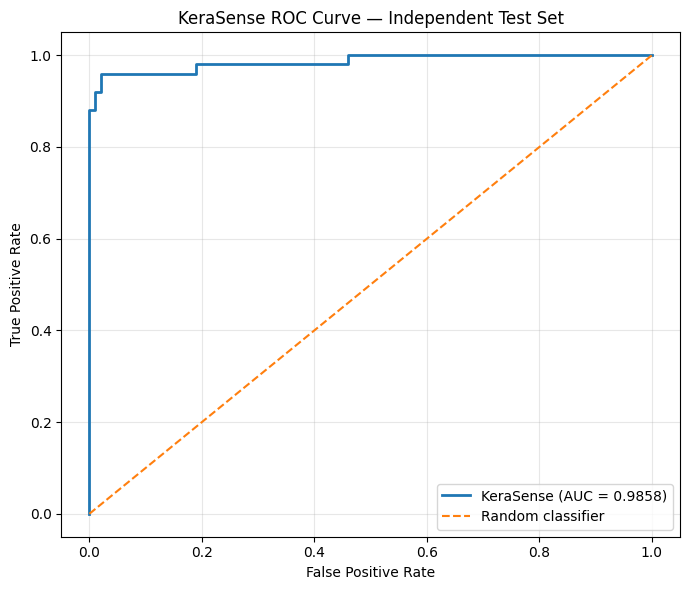

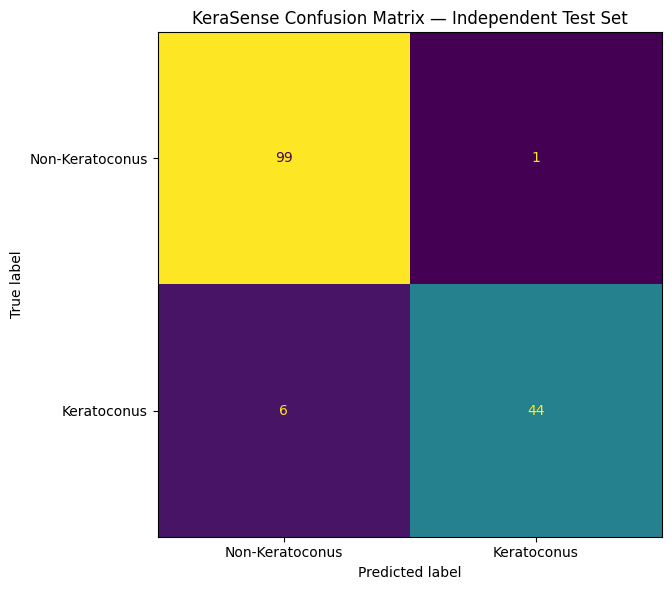

STEP 30 COMPLETE

ROC-AUC: 0.9858

Confusion Matrix:
[[99  1]
 [ 6 44]]

TN = 99
FP = 1
FN = 6
TP = 44


In [84]:
# ============================================================
# KeraSense - STEP 30
# ROC Curve + Confusion Matrix
# ============================================================

import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    ConfusionMatrixDisplay
)

# ------------------------------------------------------------
# ROC CURVE
# ------------------------------------------------------------

fpr, tpr, roc_thresholds = roc_curve(
    test_binary_labels,
    test_binary_probs
)

roc_auc_value = roc_auc_score(
    test_binary_labels,
    test_binary_probs
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"KeraSense (AUC = {roc_auc_value:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(
    "KeraSense ROC Curve — Independent Test Set"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    test_binary_labels,
    test_binary_predictions,
    labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Non-Keratoconus",
        "Keratoconus"
    ]
)

disp.plot(
    ax=ax,
    values_format="d",
    colorbar=False
)

ax.set_title(
    "KeraSense Confusion Matrix — Independent Test Set"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# FINAL SUMMARY
# ------------------------------------------------------------

print("=" * 70)
print("STEP 30 COMPLETE")
print("=" * 70)

print(f"\nROC-AUC: {roc_auc_value:.4f}")

print("\nConfusion Matrix:")
print(cm)

print("\nTN =", tn)
print("FP =", fp)
print("FN =", fn)
print("TP =", tp)

In [85]:

# ============================================================
# KeraSense - STEP 31A
# Binary Grad-CAM Setup
# ============================================================

# Make sure the final binary model is in evaluation mode
binary_model.eval()

# Enable gradients in the backbone
# Required because Grad-CAM needs activation gradients.
for param in binary_model.backbone.parameters():
    param.requires_grad = True


# Target convolutional layer
binary_gradcam_target_layer = (
    binary_model.backbone.features[-1]
)

print("=" * 70)
print("BINARY KERASENSE GRAD-CAM READY")
print("=" * 70)

print("\nTarget layer:")
print("binary_model.backbone.features[-1]")

print("\nNumber of corneal maps:", len(MAP_TYPES))

print("\nMaps:")
for i, map_name in enumerate(MAP_TYPES, 1):
    print(f"{i}. {map_name}")

BINARY KERASENSE GRAD-CAM READY

Target layer:
binary_model.backbone.features[-1]

Number of corneal maps: 7

Maps:
1. Sag_A
2. Sag_P
3. Elv_A
4. Elv_P
5. CT_A
6. EC_A
7. EC_P


In [86]:

# ============================================================
# KeraSense - STEP 31B
# Capture 7-map Grad-CAM Activations + Gradients
# ============================================================

# ------------------------------------------------------------
# Select one independent-test eye
# ------------------------------------------------------------

gradcam_index = 0

gradcam_maps, gradcam_true_label = test_binary_dataset[
    gradcam_index
]

# Add batch dimension
gradcam_input = gradcam_maps.unsqueeze(0).to(device)

# ------------------------------------------------------------
# Storage
# ------------------------------------------------------------

gradcam_activations = []
gradcam_gradients = []


# ------------------------------------------------------------
# Hook
# ------------------------------------------------------------

def binary_gradcam_forward_hook(module, input, output):

    # Save activation for this map
    gradcam_activations.append(output)

    # Capture gradient associated with this activation
    if output.requires_grad:

        output.register_hook(
            lambda grad: gradcam_gradients.append(grad)
        )


# Register hook
gradcam_handle = (
    binary_gradcam_target_layer.register_forward_hook(
        binary_gradcam_forward_hook
    )
)


# ------------------------------------------------------------
# Forward + Backward
# ------------------------------------------------------------

binary_model.zero_grad(set_to_none=True)

output = binary_model(
    gradcam_input
)

probabilities = torch.softmax(
    output,
    dim=1
)

kc_probability = probabilities[0, 1]

predicted_label = int(
    torch.argmax(output, dim=1).item()
)

# Backpropagate KC score
kc_probability.backward()


# ------------------------------------------------------------
# Remove hook
# ------------------------------------------------------------

gradcam_handle.remove()


# ------------------------------------------------------------
# Verify capture
# ------------------------------------------------------------

print("=" * 70)
print("BINARY KERASENSE GRAD-CAM CAPTURE")
print("=" * 70)

print("\nTest eye index:", gradcam_index)

print(
    "True label:",
    "Keratoconus"
    if gradcam_true_label == 1
    else "Non-Keratoconus"
)

print(
    "Predicted:",
    "Keratoconus"
    if predicted_label == 1
    else "Non-Keratoconus"
)

print(
    "KC probability:",
    f"{kc_probability.item():.4f}"
)

print(
    "\nActivations captured:",
    len(gradcam_activations)
)

print(
    "Gradients captured:",
    len(gradcam_gradients)
)

print("\nExpected:")
print("Activations = 7")
print("Gradients    = 7")

BINARY KERASENSE GRAD-CAM CAPTURE

Test eye index: 0
True label: Keratoconus
Predicted: Keratoconus
KC probability: 0.9574

Activations captured: 7
Gradients captured: 7

Expected:
Activations = 7
Gradients    = 7


In [87]:

# ============================================================
# KeraSense - STEP 31C
# Generate 7 Grad-CAM Heatmaps
# ============================================================

import torch
import torch.nn.functional as F
import numpy as np


def create_binary_gradcam(
    activation,
    gradient
):
    """
    Create a Grad-CAM heatmap from one
    activation-gradient pair.
    """

    # Remove batch dimension
    activation = activation.detach().cpu()[0]
    gradient = gradient.detach().cpu()[0]

    # Global-average-pool gradients
    weights = gradient.mean(
        dim=(1, 2)
    )

    # Weighted activation maps
    cam = torch.sum(
        weights[:, None, None] * activation,
        dim=0
    )

    # Keep positive contributions
    cam = F.relu(cam)

    # Normalize to [0, 1]
    cam_min = cam.min()
    cam_max = cam.max()

    if (cam_max - cam_min) > 1e-8:

        cam = (
            cam - cam_min
        ) / (
            cam_max - cam_min
        )

    else:

        cam = torch.zeros_like(cam)

    return cam.numpy()


# ------------------------------------------------------------
# Generate all 7 CAMs
# ------------------------------------------------------------

binary_gradcam_maps = []

for i in range(7):

    cam = create_binary_gradcam(
        gradcam_activations[i],
        gradcam_gradients[i]
    )

    binary_gradcam_maps.append(cam)


# ------------------------------------------------------------
# Verify
# ------------------------------------------------------------

print("=" * 70)
print("7-MAP BINARY GRAD-CAM GENERATED")
print("=" * 70)

for i, (map_name, cam) in enumerate(
    zip(MAP_TYPES, binary_gradcam_maps),
    start=1
):

    print(
        f"{i}. {map_name:6s} | "
        f"Shape: {cam.shape} | "
        f"Range: "
        f"{cam.min():.4f} - {cam.max():.4f}"
    )

print("\nTotal Grad-CAM maps:", len(binary_gradcam_maps))

7-MAP BINARY GRAD-CAM GENERATED
1. Sag_A  | Shape: (7, 7) | Range: 0.0000 - 1.0000
2. Sag_P  | Shape: (7, 7) | Range: 0.0000 - 1.0000
3. Elv_A  | Shape: (7, 7) | Range: 0.0000 - 1.0000
4. Elv_P  | Shape: (7, 7) | Range: 0.0000 - 1.0000
5. CT_A   | Shape: (7, 7) | Range: 0.0000 - 1.0000
6. EC_A   | Shape: (7, 7) | Range: 0.0000 - 1.0000
7. EC_P   | Shape: (7, 7) | Range: 0.0000 - 1.0000

Total Grad-CAM maps: 7


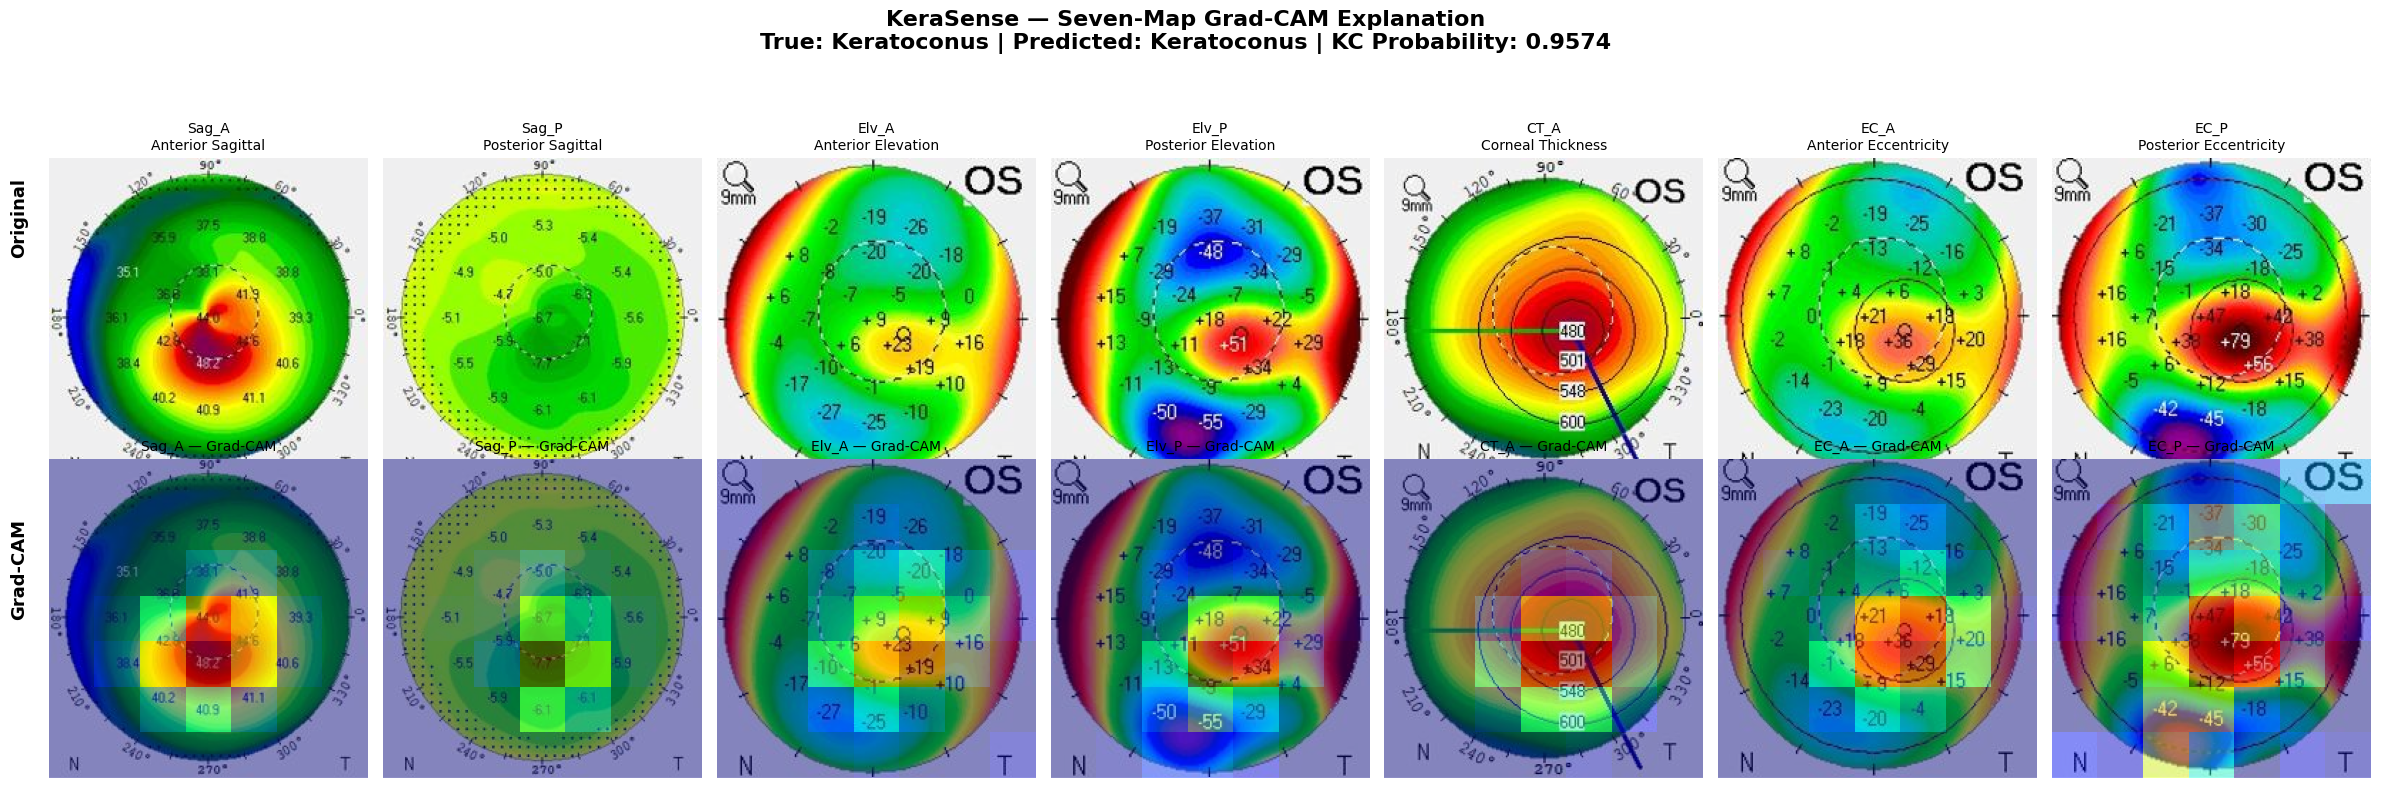

STEP 31D COMPLETE

True label: Keratoconus
Predicted: Keratoconus
KC probability: 0.9574

Seven-map Grad-CAM visualization generated successfully.


In [88]:

# ============================================================
# KeraSense - STEP 31D
# Final 7-Map Grad-CAM Visualization
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image


# ------------------------------------------------------------
# Convert tensors back to displayable images
# ------------------------------------------------------------

display_images = []

for i in range(7):

    img = gradcam_maps[i].detach().cpu()

    # CHW -> HWC
    img = img.permute(1, 2, 0).numpy()

    # Undo ImageNet normalization
    mean = np.array(
        [0.485, 0.456, 0.406]
    )

    std = np.array(
        [0.229, 0.224, 0.225]
    )

    img = img * std + mean

    img = np.clip(
        img,
        0,
        1
    )

    display_images.append(img)


# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    7,
    figsize=(24, 8)
)


# ------------------------------------------------------------
# Map titles
# ------------------------------------------------------------

map_titles = [
    "Sag_A\nAnterior Sagittal",
    "Sag_P\nPosterior Sagittal",
    "Elv_A\nAnterior Elevation",
    "Elv_P\nPosterior Elevation",
    "CT_A\nCorneal Thickness",
    "EC_A\nAnterior Eccentricity",
    "EC_P\nPosterior Eccentricity"
]


# ------------------------------------------------------------
# Plot original maps
# ------------------------------------------------------------

for i in range(7):

    axes[0, i].imshow(
        display_images[i]
    )

    axes[0, i].set_title(
        map_titles[i],
        fontsize=10
    )

    axes[0, i].axis("off")


# ------------------------------------------------------------
# Plot Grad-CAM overlays
# ------------------------------------------------------------

for i in range(7):

    axes[1, i].imshow(
        display_images[i]
    )

    axes[1, i].imshow(
        binary_gradcam_maps[i],
        cmap="jet",
        alpha=0.45,
        extent=(
            0,
            display_images[i].shape[1],
            display_images[i].shape[0],
            0
        )
    )

    axes[1, i].set_title(
        f"{MAP_TYPES[i]} — Grad-CAM",
        fontsize=10
    )

    axes[1, i].axis("off")


# ------------------------------------------------------------
# Overall title
# ------------------------------------------------------------

true_name = (
    "Keratoconus"
    if gradcam_true_label == 1
    else "Non-Keratoconus"
)

pred_name = (
    "Keratoconus"
    if predicted_label == 1
    else "Non-Keratoconus"
)

fig.suptitle(
    "KeraSense — Seven-Map Grad-CAM Explanation\n"
    f"True: {true_name} | "
    f"Predicted: {pred_name} | "
    f"KC Probability: {kc_probability.item():.4f}",
    fontsize=16,
    fontweight="bold"
)


# ------------------------------------------------------------
# Row labels
# ------------------------------------------------------------

fig.text(
    0.01,
    0.72,
    "Original",
    rotation=90,
    fontsize=13,
    fontweight="bold",
    va="center"
)

fig.text(
    0.01,
    0.28,
    "Grad-CAM",
    rotation=90,
    fontsize=13,
    fontweight="bold",
    va="center"
)


plt.tight_layout(
    rect=[0.02, 0, 1, 0.90]
)

plt.show()


print("=" * 70)
print("STEP 31D COMPLETE")
print("=" * 70)

print("\nTrue label:", true_name)
print("Predicted:", pred_name)
print(
    "KC probability:",
    f"{kc_probability.item():.4f}"
)

print("\nSeven-map Grad-CAM visualization generated successfully.")

In [89]:

# ============================================================
# KeraSense - STEP 31E
# Find Correctly Detected Keratoconus Test Eye
# ============================================================

kc_correct_indices = np.where(
    (test_binary_labels == 1) &
    (test_binary_predictions == 1)
)[0]

print("=" * 70)
print("CORRECTLY DETECTED KERATOCONUS CASES")
print("=" * 70)

print(
    "\nNumber of correctly detected KC eyes:",
    len(kc_correct_indices)
)

print(
    "Total KC eyes:",
    np.sum(test_binary_labels == 1)
)

print(
    "KC sensitivity:",
    f"{sensitivity * 100:.2f}%"
)

print("\nFirst correctly detected KC indices:")

for idx in kc_correct_indices[:10]:

    print(
        f"Index {idx:3d} | "
        f"KC probability = "
        f"{test_binary_probs[idx]:.4f}"
    )

CORRECTLY DETECTED KERATOCONUS CASES

Number of correctly detected KC eyes: 44
Total KC eyes: 50
KC sensitivity: 88.00%

First correctly detected KC indices:
Index   0 | KC probability = 0.9574
Index   1 | KC probability = 0.9622
Index   2 | KC probability = 0.6284
Index   3 | KC probability = 0.9743
Index   4 | KC probability = 0.9636
Index   5 | KC probability = 0.8670
Index   6 | KC probability = 0.8819
Index   7 | KC probability = 0.9347
Index   8 | KC probability = 0.9307
Index   9 | KC probability = 0.8870


In [90]:

# ============================================================
# KeraSense - STEP 31F
# Grad-CAM for Correctly Detected Keratoconus Case
# ============================================================

# Select the correctly detected KC eye
gradcam_index = int(kc_correct_indices[0])

# Get the 7-map sample
gradcam_maps, gradcam_true_label = test_binary_dataset[
    gradcam_index
]

# Add batch dimension
gradcam_input = gradcam_maps.unsqueeze(0).to(device)


# ------------------------------------------------------------
# Storage
# ------------------------------------------------------------

gradcam_activations = []
gradcam_gradients = []


# ------------------------------------------------------------
# Hook
# ------------------------------------------------------------

def kc_gradcam_forward_hook(module, input, output):

    gradcam_activations.append(output)

    if output.requires_grad:

        output.register_hook(
            lambda grad: gradcam_gradients.append(grad)
        )


kc_gradcam_handle = (
    binary_gradcam_target_layer.register_forward_hook(
        kc_gradcam_forward_hook
    )
)


# ------------------------------------------------------------
# Forward + Backward
# ------------------------------------------------------------

binary_model.zero_grad(set_to_none=True)

output = binary_model(
    gradcam_input
)

probabilities = torch.softmax(
    output,
    dim=1
)

kc_probability = probabilities[0, 1]

predicted_label = int(
    torch.argmax(output, dim=1).item()
)

# Backpropagate KC probability
kc_probability.backward()


# Remove hook
kc_gradcam_handle.remove()


# ------------------------------------------------------------
# Generate 7 CAMs
# ------------------------------------------------------------

binary_gradcam_maps = []

for i in range(7):

    cam = create_binary_gradcam(
        gradcam_activations[i],
        gradcam_gradients[i]
    )

    binary_gradcam_maps.append(cam)


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("=" * 70)
print("KERASENSE KC GRAD-CAM CASE")
print("=" * 70)

print("\nTest eye index:", gradcam_index)

print(
    "True label:",
    "Keratoconus"
    if gradcam_true_label == 1
    else "Non-Keratoconus"
)

print(
    "Predicted:",
    "Keratoconus"
    if predicted_label == 1
    else "Non-Keratoconus"
)

print(
    "KC probability:",
    f"{kc_probability.item():.4f}"
)

print(
    "\nActivations:",
    len(gradcam_activations)
)

print(
    "Gradients:",
    len(gradcam_gradients)
)

print(
    "Grad-CAM maps:",
    len(binary_gradcam_maps)
)

KERASENSE KC GRAD-CAM CASE

Test eye index: 0
True label: Keratoconus
Predicted: Keratoconus
KC probability: 0.9574

Activations: 7
Gradients: 7
Grad-CAM maps: 7


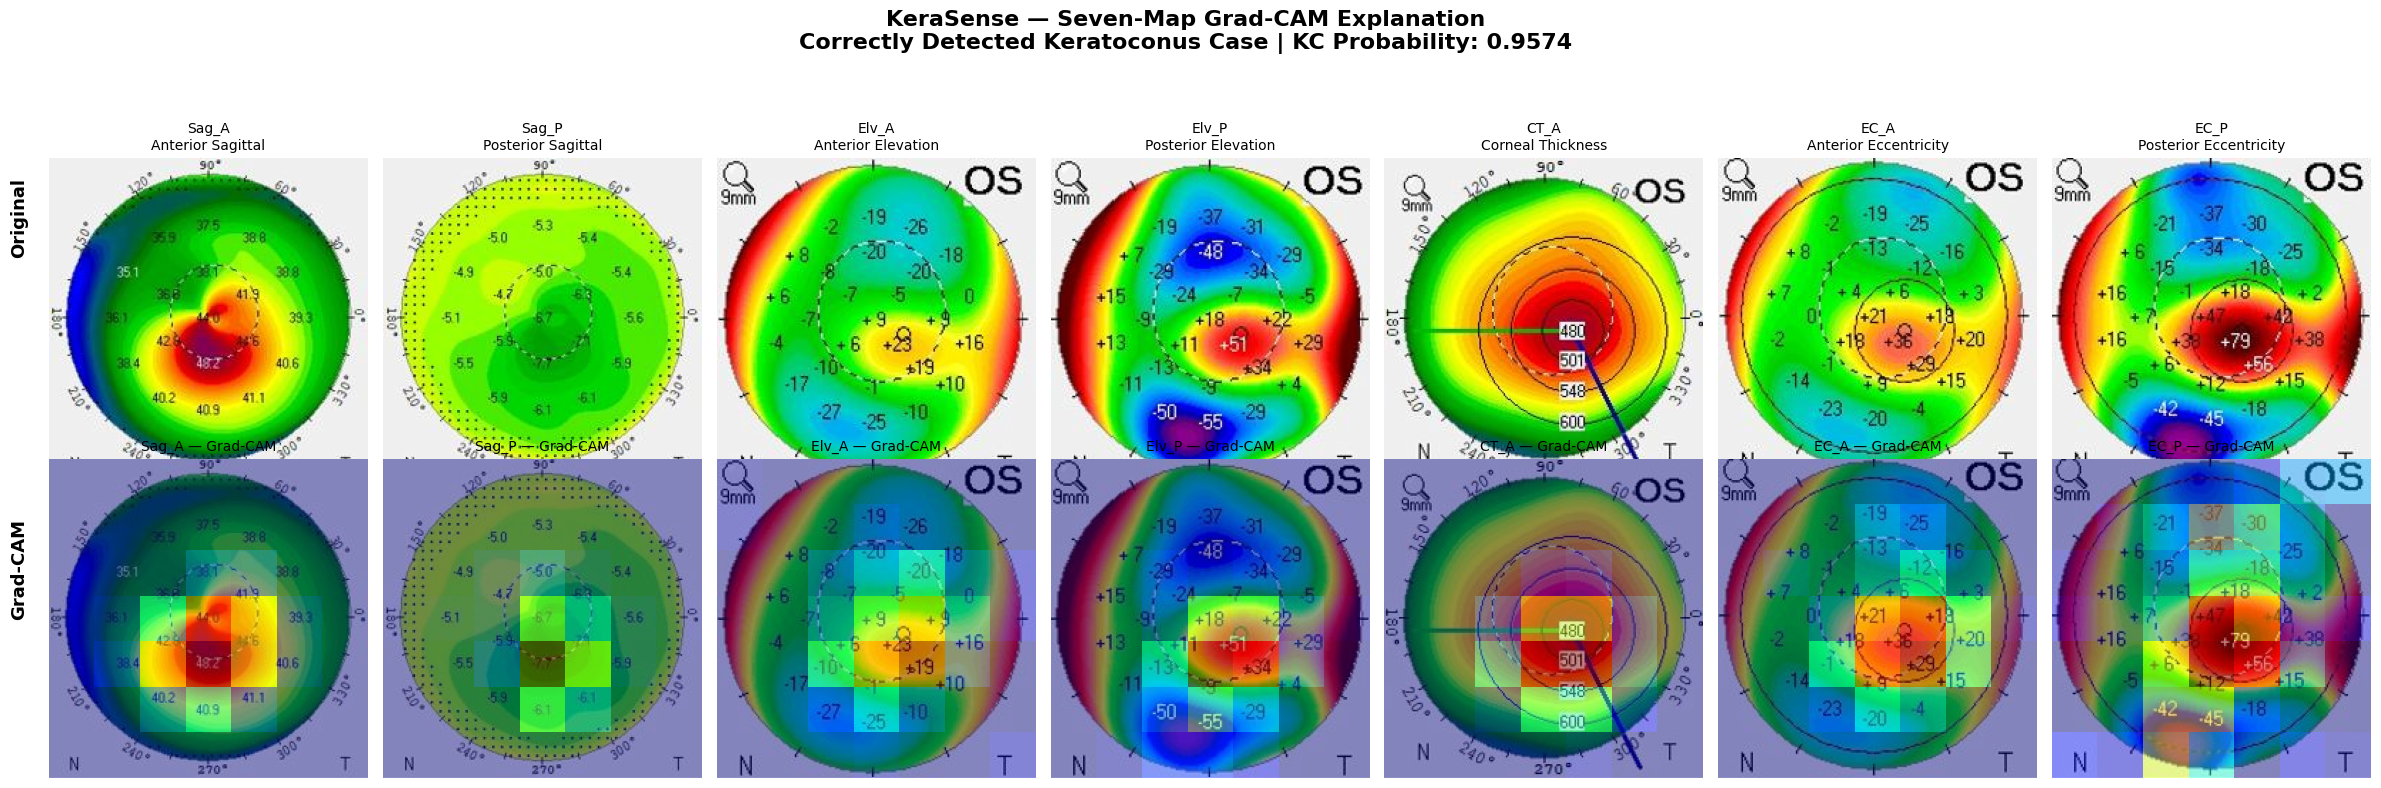

STEP 31G COMPLETE

Test eye index: 0
True label: Keratoconus
Predicted: Keratoconus
KC probability: 0.9574

Seven-map KC Grad-CAM visualization generated.


In [91]:

# ============================================================
# KeraSense - STEP 31G
# Final KC Seven-Map Grad-CAM Visualization
# ============================================================

import matplotlib.pyplot as plt
import numpy as np


# ------------------------------------------------------------
# Convert normalized tensors back to displayable images
# ------------------------------------------------------------

display_images = []

for i in range(7):

    img = gradcam_maps[i].detach().cpu()

    # CHW -> HWC
    img = img.permute(1, 2, 0).numpy()

    # Undo ImageNet normalization
    mean = np.array(
        [0.485, 0.456, 0.406]
    )

    std = np.array(
        [0.229, 0.224, 0.225]
    )

    img = img * std + mean

    img = np.clip(
        img,
        0,
        1
    )

    display_images.append(img)


# ------------------------------------------------------------
# Figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    7,
    figsize=(24, 8)
)


# ------------------------------------------------------------
# Titles
# ------------------------------------------------------------

map_titles = [
    "Sag_A\nAnterior Sagittal",
    "Sag_P\nPosterior Sagittal",
    "Elv_A\nAnterior Elevation",
    "Elv_P\nPosterior Elevation",
    "CT_A\nCorneal Thickness",
    "EC_A\nAnterior Eccentricity",
    "EC_P\nPosterior Eccentricity"
]


# ------------------------------------------------------------
# Original maps
# ------------------------------------------------------------

for i in range(7):

    axes[0, i].imshow(
        display_images[i]
    )

    axes[0, i].set_title(
        map_titles[i],
        fontsize=10
    )

    axes[0, i].axis("off")


# ------------------------------------------------------------
# Grad-CAM overlays
# ------------------------------------------------------------

for i in range(7):

    axes[1, i].imshow(
        display_images[i]
    )

    axes[1, i].imshow(
        binary_gradcam_maps[i],
        cmap="jet",
        alpha=0.45,
        extent=(
            0,
            display_images[i].shape[1],
            display_images[i].shape[0],
            0
        )
    )

    axes[1, i].set_title(
        f"{MAP_TYPES[i]} — Grad-CAM",
        fontsize=10
    )

    axes[1, i].axis("off")


# ------------------------------------------------------------
# Overall title
# ------------------------------------------------------------

fig.suptitle(
    "KeraSense — Seven-Map Grad-CAM Explanation\n"
    "Correctly Detected Keratoconus Case | "
    f"KC Probability: {kc_probability.item():.4f}",
    fontsize=16,
    fontweight="bold"
)


# ------------------------------------------------------------
# Row labels
# ------------------------------------------------------------

fig.text(
    0.01,
    0.72,
    "Original",
    rotation=90,
    fontsize=13,
    fontweight="bold",
    va="center"
)

fig.text(
    0.01,
    0.28,
    "Grad-CAM",
    rotation=90,
    fontsize=13,
    fontweight="bold",
    va="center"
)


plt.tight_layout(
    rect=[0.02, 0, 1, 0.90]
)

plt.show()


print("=" * 70)
print("STEP 31G COMPLETE")
print("=" * 70)

print("\nTest eye index:", gradcam_index)
print("True label: Keratoconus")
print("Predicted: Keratoconus")
print(
    "KC probability:",
    f"{kc_probability.item():.4f}"
)

print("\nSeven-map KC Grad-CAM visualization generated.")

In [92]:

# ============================================================
# KeraSense - STEP 32A
# Final Reusable Inference Function
# ============================================================

from PIL import Image
import torch


def kerasense_predict(
    map_paths,
    model=binary_model,
    threshold=0.50
):
    """
    Predict Keratoconus vs Non-Keratoconus
    from seven corneal maps.

    map_paths must follow MAP_TYPES order:
    [Sag_A, Sag_P, Elv_A, Elv_P,
     CT_A, EC_A, EC_P]
    """

    if len(map_paths) != 7:
        raise ValueError(
            "KeraSense requires exactly 7 corneal maps."
        )

    model.eval()

    processed_maps = []

    for image_path in map_paths:

        image = Image.open(
            image_path
        ).convert("RGB")

        image = val_transform(
            image
        )

        processed_maps.append(
            image
        )

    # 7 × C × H × W
    maps_tensor = torch.stack(
        processed_maps
    )

    # 1 × 7 × C × H × W
    maps_tensor = maps_tensor.unsqueeze(0)

    maps_tensor = maps_tensor.to(device)

    with torch.no_grad():

        outputs = model(
            maps_tensor
        )

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        kc_probability = (
            probabilities[0, 1]
            .item()
        )

    prediction = (
        "Keratoconus"
        if kc_probability >= threshold
        else "Non-Keratoconus"
    )

    return {
        "prediction": prediction,
        "kc_probability": kc_probability,
        "non_kc_probability": (
            1.0 - kc_probability
        ),
        "threshold": threshold,
        "maps_analyzed": 7,
        "map_types": MAP_TYPES
    }


print("=" * 70)
print("KERASENSE INFERENCE FUNCTION READY")
print("=" * 70)

print("\nRequired maps:", len(MAP_TYPES))

for i, map_name in enumerate(
    MAP_TYPES,
    start=1
):
    print(f"{i}. {map_name}")

print("\nThreshold: 0.50")
print("Model: Binary KeraSense")
print("Task: Keratoconus vs Non-Keratoconus")

KERASENSE INFERENCE FUNCTION READY

Required maps: 7
1. Sag_A
2. Sag_P
3. Elv_A
4. Elv_P
5. CT_A
6. EC_A
7. EC_P

Threshold: 0.50
Model: Binary KeraSense
Task: Keratoconus vs Non-Keratoconus


In [93]:

# ============================================================
# KeraSense - STEP 32B
# Test Final Inference Pipeline
# ============================================================

test_index = 50

# Get the seven map paths for this eye
test_row = test_df.iloc[test_index]

test_map_paths = [
    test_row[map_type]
    for map_type in MAP_TYPES
]

# Run KeraSense
result = kerasense_predict(
    test_map_paths,
    model=binary_model,
    threshold=0.50
)


# ------------------------------------------------------------
# Display result
# ------------------------------------------------------------

print("=" * 70)
print("KERASENSE FINAL INFERENCE TEST")
print("=" * 70)

print("\nTest eye index:", test_index)

print("\nPrediction:")
print(
    ">>>",
    result["prediction"]
)

print(
    "\nKC Probability:",
    f"{result['kc_probability']:.4f}"
)

print(
    "KC Probability:",
    f"{result['kc_probability'] * 100:.2f}%"
)

print(
    "\nNon-KC Probability:",
    f"{result['non_kc_probability'] * 100:.2f}%"
)

print(
    "\nDecision Threshold:",
    f"{result['threshold']:.2f}"
)

print(
    "\nMaps analyzed:",
    result["maps_analyzed"]
)

print("\nMap types:")

for i, map_name in enumerate(
    result["map_types"],
    start=1
):
    print(f"{i}. {map_name}")


print("\n" + "=" * 70)
print("INFERENCE TEST COMPLETE")
print("=" * 70)

KERASENSE FINAL INFERENCE TEST

Test eye index: 50

Prediction:
>>> Non-Keratoconus

KC Probability: 0.0062
KC Probability: 0.62%

Non-KC Probability: 99.38%

Decision Threshold: 0.50

Maps analyzed: 7

Map types:
1. Sag_A
2. Sag_P
3. Elv_A
4. Elv_P
5. CT_A
6. EC_A
7. EC_P

INFERENCE TEST COMPLETE


In [94]:
# ============================================================
# KeraSense - STEP 32D
# Locate the 7 maps for Test Eye Index 50
# ============================================================

test_index = 50
test_row = test_df.iloc[test_index]

print("=" * 70)
print("7 CORNEAL MAPS FOR TEST EYE INDEX 50")
print("=" * 70)

for i, map_type in enumerate(MAP_TYPES, start=1):
    image_path = test_row[map_type]

    print(f"\n{i}. {map_type}")
    print("   Filename:", os.path.basename(image_path))
    print("   Path:", image_path)

7 CORNEAL MAPS FOR TEST EYE INDEX 50

1. Sag_A
   Filename: NOR_12_Sag_A.jpg
   Path: /kaggle/input/keratoconus-detection/Independent Test Set/Independent Test Set/Normal/case12/NOR_12_Sag_A.jpg

2. Sag_P
   Filename: NOR_12_Sag_P.jpg
   Path: /kaggle/input/keratoconus-detection/Independent Test Set/Independent Test Set/Normal/case12/NOR_12_Sag_P.jpg

3. Elv_A
   Filename: NOR_12_Elv_A.jpg
   Path: /kaggle/input/keratoconus-detection/Independent Test Set/Independent Test Set/Normal/case12/NOR_12_Elv_A.jpg

4. Elv_P
   Filename: NOR_12_Elv_P.jpg
   Path: /kaggle/input/keratoconus-detection/Independent Test Set/Independent Test Set/Normal/case12/NOR_12_Elv_P.jpg

5. CT_A
   Filename: NOR_12_CT_A.jpg
   Path: /kaggle/input/keratoconus-detection/Independent Test Set/Independent Test Set/Normal/case12/NOR_12_CT_A.jpg

6. EC_A
   Filename: NOR_12_EC_A.jpg
   Path: /kaggle/input/keratoconus-detection/Independent Test Set/Independent Test Set/Normal/case12/NOR_12_EC_A.jpg

7. EC_P
   Filename:

In [95]:
# ============================================================
# KeraSense - STEP 32E
# Prepare the 7 Test Images for Upload
# ============================================================

import shutil
import os

test_index = 50
test_row = test_df.iloc[test_index]

upload_dir = "/content/kerasense_test_eye_50"
os.makedirs(upload_dir, exist_ok=True)

print("=" * 70)
print("PREPARING 7 CORNEAL MAPS")
print("=" * 70)

for map_type in MAP_TYPES:

    source_path = test_row[map_type]

    filename = os.path.basename(source_path)

    destination_path = os.path.join(
        upload_dir,
        filename
    )

    shutil.copy2(
        source_path,
        destination_path
    )

    print(f"{map_type:8s} → {filename}")


print("\n" + "=" * 70)
print("READY FOR UPLOAD")
print("=" * 70)

print("\nFolder:")
print(upload_dir)

PREPARING 7 CORNEAL MAPS
Sag_A    → NOR_12_Sag_A.jpg
Sag_P    → NOR_12_Sag_P.jpg
Elv_A    → NOR_12_Elv_A.jpg
Elv_P    → NOR_12_Elv_P.jpg
CT_A     → NOR_12_CT_A.jpg
EC_A     → NOR_12_EC_A.jpg
EC_P     → NOR_12_EC_P.jpg

READY FOR UPLOAD

Folder:
/content/kerasense_test_eye_50


In [96]:
# ============================================================
# KeraSense - STEP 32G
# Create ZIP of the 7 test maps
# ============================================================

import shutil

zip_path = shutil.make_archive(
    "/content/KeraSense_Test_Eye_50",
    "zip",
    "/content/kerasense_test_eye_50"
)

print("ZIP created successfully:")
print(zip_path)

ZIP created successfully:
/content/KeraSense_Test_Eye_50.zip


In [97]:
from google.colab import files

files.download("/content/KeraSense_Test_Eye_50.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [99]:
# ============================================================
# KeraSense - Interface Recovery
# Fix: NameError - predict_button is not defined
# ============================================================

import os
import ipywidgets as widgets
from IPython.display import display


# ------------------------------------------------------------
# Create fresh upload widgets
# ------------------------------------------------------------

upload_widgets = {}

for map_name in MAP_TYPES:
    upload_widgets[map_name] = widgets.FileUpload(
        accept="image/*",
        multiple=False,
        description=map_name
    )


# ------------------------------------------------------------
# Create button and output
# ------------------------------------------------------------

predict_button = widgets.Button(
    description="Run KeraSense",
    button_style="primary"
)

output_box = widgets.Output()


# ------------------------------------------------------------
# Prediction callback
# ------------------------------------------------------------

def run_kerasense_final(_):

    with output_box:
        output_box.clear_output()

        uploaded_paths = []

        # Check and save all 7 maps
        for map_name in MAP_TYPES:

            uploaded = upload_widgets[map_name].value

            if not uploaded:
                print(f"ERROR: Please upload {map_name}.")
                return

            # Handle current ipywidgets format
            if isinstance(uploaded, tuple):
                file_info = uploaded[0]

                filename = file_info.get("name")
                content = file_info.get("content")

            elif isinstance(uploaded, dict):

                if "name" in uploaded:
                    filename = uploaded.get("name")
                    content = uploaded.get("content")
                else:
                    filename = next(iter(uploaded))
                    file_info = uploaded[filename]

                    filename = file_info.get(
                        "name",
                        filename
                    )

                    content = file_info.get("content")

            else:
                print(f"ERROR: Could not read {map_name}.")
                return

            if content is None:
                print(f"ERROR: Could not read {map_name}.")
                return

            temp_path = os.path.join(
                "/tmp",
                f"kerasense_{map_name}_{filename}"
            )

            with open(temp_path, "wb") as f:
                f.write(content)

            uploaded_paths.append(temp_path)


        # ----------------------------------------------------
        # Run the trained KeraSense model
        # ----------------------------------------------------

        result = kerasense_predict(
            uploaded_paths,
            model=binary_model,
            threshold=0.50
        )


        # ----------------------------------------------------
        # Display result
        # ----------------------------------------------------

        print("=" * 70)
        print("KERASENSE RESULT")
        print("=" * 70)

        print("\nPrediction:")
        print(">>>", result["prediction"])

        print(
            "\nKeratoconus Probability:",
            f"{result['kc_probability'] * 100:.2f}%"
        )

        print(
            "Non-Keratoconus Probability:",
            f"{result['non_kc_probability'] * 100:.2f}%"
        )

        print(
            "\nDecision Threshold:",
            f"{result['threshold']:.2f}"
        )

        print(
            "\nMaps analyzed:",
            result["maps_analyzed"]
        )

        print("\n" + "=" * 70)


# ------------------------------------------------------------
# Attach callback
# ------------------------------------------------------------

predict_button.on_click(run_kerasense_final)


# ------------------------------------------------------------
# Display fresh interface
# ------------------------------------------------------------

print("=" * 70)
print("KERASENSE - 7-MAP KERATOCONUS SCREENING")
print("=" * 70)

print("\nUpload exactly one image for each map:\n")

for map_name in MAP_TYPES:
    display(upload_widgets[map_name])

display(predict_button)
display(output_box)

print("\nInterface ready.")

KERASENSE - 7-MAP KERATOCONUS SCREENING

Upload exactly one image for each map:



FileUpload(value={}, accept='image/*', description='Sag_A')

FileUpload(value={}, accept='image/*', description='Sag_P')

FileUpload(value={}, accept='image/*', description='Elv_A')

FileUpload(value={}, accept='image/*', description='Elv_P')

...

FileUpload(value={}, accept='image/*', description='EC_A')

FileUpload(value={}, accept='image/*', description='EC_P')

Button(button_style='primary', description='Run KeraSense', style=ButtonStyle())

Output()


Interface ready.


In [100]:
# ============================================================
# KeraSense - STEP 32H
# Fix FileUpload Compatibility
# ============================================================

def run_kerasense_fixed(_):

    with output_box:
        output_box.clear_output()

        uploaded_paths = []

        for map_name in MAP_TYPES:

            uploaded = upload_widgets[map_name].value

            if not uploaded:
                print(
                    f"ERROR: Please upload the {map_name} map."
                )
                return

            # ------------------------------------------------
            # Handle different ipywidgets FileUpload formats
            # ------------------------------------------------

            if isinstance(uploaded, dict):

                # Format: {"filename": {...file information...}}
                if "name" in uploaded:
                    file_info = uploaded
                    filename = file_info.get("name")
                    content = file_info.get("content")

                else:
                    filename = next(iter(uploaded))
                    file_info = uploaded[filename]

                    if isinstance(file_info, dict):
                        content = file_info.get("content")
                    else:
                        content = file_info

            else:

                # Format: tuple/list of file dictionaries
                file_info = uploaded[0]

                filename = file_info.get("name")

                if filename is None:
                    filename = file_info.get(
                        "metadata",
                        {}
                    ).get("name")

                content = file_info.get("content")

            if content is None:
                print(
                    f"ERROR: Could not read {map_name}."
                )
                return

            # ------------------------------------------------
            # Save uploaded file temporarily
            # ------------------------------------------------

            temp_path = os.path.join(
                "/tmp",
                f"kerasense_{map_name}_{filename}"
            )

            with open(temp_path, "wb") as f:
                f.write(content)

            uploaded_paths.append(temp_path)

        # ----------------------------------------------------
        # Run KeraSense
        # ----------------------------------------------------

        result = kerasense_predict(
            uploaded_paths,
            model=binary_model,
            threshold=0.50
        )

        # ----------------------------------------------------
        # Display result
        # ----------------------------------------------------

        print("=" * 70)
        print("KERASENSE RESULT")
        print("=" * 70)

        print(
            "\nPrediction:",
            result["prediction"]
        )

        print(
            "\nKeratoconus Probability:",
            f"{result['kc_probability'] * 100:.2f}%"
        )

        print(
            "Non-Keratoconus Probability:",
            f"{result['non_kc_probability'] * 100:.2f}%"
        )

        print(
            "\nDecision Threshold:",
            f"{result['threshold']:.2f}"
        )

        print(
            "\nMaps analyzed:",
            result["maps_analyzed"]
        )

        print("\n" + "=" * 70)


# Replace the old callback
predict_button.on_click(run_kerasense_fixed)

print("KeraSense upload interface fixed successfully.")
print("Upload all 7 maps and click 'Run KeraSense'.")

KeraSense upload interface fixed successfully.
Upload all 7 maps and click 'Run KeraSense'.


In [101]:
# ============================================================
# KeraSense - STEP 32I
# Replace Old Callback Completely
# ============================================================

# Remove ALL existing click callbacks
predict_button._click_handlers.callbacks.clear()


# Attach only the corrected callback
predict_button.on_click(run_kerasense_fixed)


print("=" * 70)
print("OLD CALLBACK REMOVED")
print("NEW CALLBACK ATTACHED")
print("=" * 70)
print("\nYour 7 uploaded files are still selected.")
print("Now click: Run KeraSense")

OLD CALLBACK REMOVED
NEW CALLBACK ATTACHED

Your 7 uploaded files are still selected.
Now click: Run KeraSense


In [103]:
# ============================================================
# KeraSense - Interface Recovery
# Fix: NameError - predict_button is not defined
# ============================================================

import os
import ipywidgets as widgets
from IPython.display import display


# ------------------------------------------------------------
# Create fresh upload widgets
# ------------------------------------------------------------

upload_widgets = {}

for map_name in MAP_TYPES:
    upload_widgets[map_name] = widgets.FileUpload(
        accept="image/*",
        multiple=False,
        description=map_name
    )


# ------------------------------------------------------------
# Create button and output
# ------------------------------------------------------------

predict_button = widgets.Button(
    description="Run KeraSense",
    button_style="primary"
)

output_box = widgets.Output()


# ------------------------------------------------------------
# Prediction callback
# ------------------------------------------------------------

def run_kerasense_final(_):

    with output_box:
        output_box.clear_output()

        uploaded_paths = []

        # Check and save all 7 maps
        for map_name in MAP_TYPES:

            uploaded = upload_widgets[map_name].value

            if not uploaded:
                print(f"ERROR: Please upload {map_name}.")
                return

            # Handle current ipywidgets format
            if isinstance(uploaded, tuple):
                file_info = uploaded[0]

                filename = file_info.get("name")
                content = file_info.get("content")

            elif isinstance(uploaded, dict):

                if "name" in uploaded:
                    filename = uploaded.get("name")
                    content = uploaded.get("content")
                else:
                    filename = next(iter(uploaded))
                    file_info = uploaded[filename]

                    filename = file_info.get(
                        "name",
                        filename
                    )

                    content = file_info.get("content")

            else:
                print(f"ERROR: Could not read {map_name}.")
                return

            if content is None:
                print(f"ERROR: Could not read {map_name}.")
                return

            temp_path = os.path.join(
                "/tmp",
                f"kerasense_{map_name}_{filename}"
            )

            with open(temp_path, "wb") as f:
                f.write(content)

            uploaded_paths.append(temp_path)


        # ----------------------------------------------------
        # Run the trained KeraSense model
        # ----------------------------------------------------

        result = kerasense_predict(
            uploaded_paths,
            model=binary_model,
            threshold=0.50
        )


        # ----------------------------------------------------
        # Display result
        # ----------------------------------------------------

        print("=" * 70)
        print("KERASENSE RESULT")
        print("=" * 70)

        print("\nPrediction:")
        print(">>>", result["prediction"])

        print(
            "\nKeratoconus Probability:",
            f"{result['kc_probability'] * 100:.2f}%"
        )

        print(
            "Non-Keratoconus Probability:",
            f"{result['non_kc_probability'] * 100:.2f}%"
        )

        print(
            "\nDecision Threshold:",
            f"{result['threshold']:.2f}"
        )

        print(
            "\nMaps analyzed:",
            result["maps_analyzed"]
        )

        print("\n" + "=" * 70)


# ------------------------------------------------------------
# Attach callback
# ------------------------------------------------------------

predict_button.on_click(run_kerasense_final)


# ------------------------------------------------------------
# Display fresh interface
# ------------------------------------------------------------

print("=" * 70)
print("KERASENSE - 7-MAP KERATOCONUS SCREENING")
print("=" * 70)

print("\nUpload exactly one image for each map:\n")

for map_name in MAP_TYPES:
    display(upload_widgets[map_name])

display(predict_button)
display(output_box)

print("\nInterface ready.")

KERASENSE - 7-MAP KERATOCONUS SCREENING

Upload exactly one image for each map:



FileUpload(value={}, accept='image/*', description='Sag_A')

FileUpload(value={}, accept='image/*', description='Sag_P')

FileUpload(value={}, accept='image/*', description='Elv_A')

FileUpload(value={}, accept='image/*', description='Elv_P')

...

FileUpload(value={}, accept='image/*', description='EC_A')

FileUpload(value={}, accept='image/*', description='EC_P')

Button(button_style='primary', description='Run KeraSense', style=ButtonStyle())

Output()


Interface ready.
